# Network Science HS26 – Enzyme Structural Graph

Analysis notebook. Run top to bottom; figures are saved to `../figures/`.

In [1]:
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from networkx.algorithms import community as nx_comm
from scipy import stats

DATA = Path("../raw_data/edgelist.txt")
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)
SEED = 42

## 0. Load the network

Note: the file lists every edge in both directions (220 rows, 110 unique edges). `nx.Graph` collapses these.

In [2]:
G = nx.read_edgelist(DATA, nodetype=int)
print(G)
print("rows in file:", sum(1 for _ in DATA.open()))
print("self-loops:", nx.number_of_selfloops(G))

Graph with 51 nodes and 110 edges
rows in file: 220
self-loops: 0


### Visual overview

Left: Kamada–Kawai layout (works well for small, sparse graphs), nodes coloured and sized by degree. Edges between consecutive node IDs (i, i+1) are drawn darker — 33 of the 50 possible pairs are linked, so the ID ordering appears to carry meaning (e.g. sequence position).
Right: adjacency matrix in node-ID order, which makes that ordering visible as a band along the diagonal plus off-diagonal stripes.

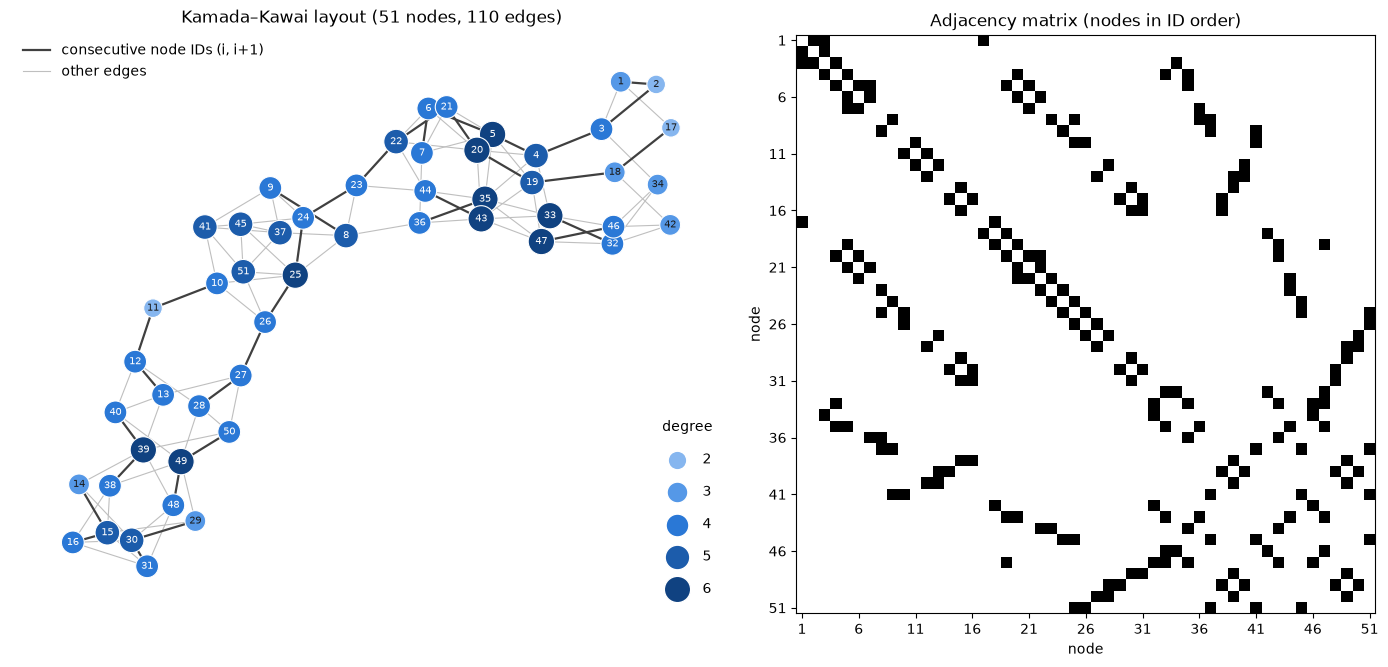

In [3]:
nodes = sorted(G.nodes())
deg = dict(G.degree())
pos = nx.kamada_kawai_layout(G)

# Degree only takes a few integer values (2–6): one discrete blue step per value, light -> dark
deg_vals = list(range(min(deg.values()), max(deg.values()) + 1))
deg_color = dict(zip(deg_vals, ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]))
def node_size(d):
    return 90 + 45 * d

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1.25, 1]})

# Node-link drawing
seq_edges = [(u, v) for u, v in G.edges() if abs(u - v) == 1]
other_edges = [(u, v) for u, v in G.edges() if abs(u - v) != 1]
nx.draw_networkx_edges(G, pos, edgelist=other_edges, ax=ax1, edge_color="0.75", width=0.8)
nx.draw_networkx_edges(G, pos, edgelist=seq_edges, ax=ax1, edge_color="0.25", width=1.6)
nx.draw_networkx_nodes(G, pos, nodelist=nodes, ax=ax1,
                       node_color=[deg_color[deg[n]] for n in nodes],
                       node_size=[node_size(deg[n]) for n in nodes],
                       edgecolors="white", linewidths=0.8)
# Dark labels on the two lightest steps, white on the rest (keeps contrast readable)
light = deg_vals[1]
nx.draw_networkx_labels(G, pos, labels={n: n for n in nodes if deg[n] <= light},
                        ax=ax1, font_size=7, font_color="#1a1a1a")
nx.draw_networkx_labels(G, pos, labels={n: n for n in nodes if deg[n] > light},
                        ax=ax1, font_size=7, font_color="white")

deg_handles = [ax1.scatter([], [], s=node_size(d), color=deg_color[d], edgecolors="white", label=d)
               for d in deg_vals]
ax1.add_artist(ax1.legend(handles=deg_handles, title="degree", loc="lower right",
                          frameon=False, labelspacing=1.3, borderpad=1))
edge_handles = [plt.Line2D([], [], color="0.25", lw=1.6, label="consecutive node IDs (i, i+1)"),
                plt.Line2D([], [], color="0.75", lw=0.8, label="other edges")]
ax1.legend(handles=edge_handles, loc="upper left", frameon=False)
ax1.set_title(f"Kamada–Kawai layout ({G.number_of_nodes()} nodes, {G.number_of_edges()} edges)")
ax1.axis("off")

# Adjacency matrix in node-ID order
A = nx.to_numpy_array(G, nodelist=nodes)
ax2.imshow(A, cmap="Greys", interpolation="nearest")
ticks = np.arange(0, len(nodes), 5)
ax2.set_xticks(ticks, [nodes[i] for i in ticks])
ax2.set_yticks(ticks, [nodes[i] for i in ticks])
ax2.set_title("Adjacency matrix (nodes in ID order)")
ax2.set_xlabel("node")
ax2.set_ylabel("node")

fig.tight_layout()
fig.savefig(FIG / "network_overview.png", dpi=150, bbox_inches="tight")
plt.show()

## 1. Connectivity and global structure

Is the network in one piece, how easily can it be split, and what is its overall shape? §1.2 then sets up the random reference graphs that §4–§8 compare against.

### 1.1 Size, connectivity and distances

In [4]:
N, L = G.number_of_nodes(), G.number_of_edges()
ecc = nx.eccentricity(G)  # largest distance from each node to any other node
diameter = nx.diameter(G, e=ecc)
radius = nx.radius(G, e=ecc)
centre = nx.center(G, e=ecc)
periphery = sorted(nx.periphery(G, e=ecc))

summary = {
    "nodes N": N,
    "links L": L,
    "density ρ": round(nx.density(G), 3),
    "mean degree ⟨k⟩": round(2 * L / N, 3),
    "connected components": nx.number_connected_components(G),
    "diameter": diameter,
    "mean distance ⟨d⟩": round(nx.average_shortest_path_length(G), 3),
    "radius": radius,
    "centre (eccentricity = radius)": centre,
    "periphery (eccentricity = diameter)": periphery,
    # A bridge / articulation point is a single link / node whose removal splits the graph
    "bridges": len(list(nx.bridges(G))),
    "articulation points": len(list(nx.articulation_points(G))),
    "node connectivity": nx.node_connectivity(G),
}
pd.Series(summary).to_frame("value")

,value
nodes N,51
links L,110
density ρ,0.086
mean degree ⟨k⟩,4.314
connected components,1
diameter,12
mean distance ⟨d⟩,5.042
radius,6
centre (eccentricity = radius),[25]
periphery (eccentricity = diameter),"[1, 2, 15, 16, 17, 30, 31, 34, 42]"


**Measurement:** density, eccentricity (diameter = largest, radius = smallest), mean shortest-path length ⟨d⟩, bridges, articulation points and node connectivity, all on the full graph. It has a single component, so no part has to be left out.

**Observation:** The 51 nodes form one component with 110 links (ρ = 0.086, ⟨k⟩ = 4.31). There are no bridges and no articulation points, and node connectivity is 2. The diameter is 12 and ⟨d⟩ = 5.04. The radius, 6, is exactly half the diameter, which is the smallest value the triangle inequality allows. One node, 25, has that eccentricity.

**Interpretation:** The graph is sparse but 2-connected: no single node or link failure disconnects it. A radius at half the diameter means the centre sits at the midpoint of the longest paths, as it would in a chain. In a compact graph most nodes have similar eccentricities, so the radius sits well above half the diameter. This is a first hint of an elongated shape; the next cells test it, and §7 compares ⟨d⟩ with random graphs.

**Caveat:** Node connectivity 2 equals the minimum degree, so cutting the two neighbours of any k = 2 node (2, 11 or 17) already reaches it. The number alone does not show whether the graph also has narrow points in the middle; the cuts below do.

In [5]:
# Distances from the centre and between periphery nodes: one rim around a core, or two separate "ends"?
dist = dict(nx.all_pairs_shortest_path_length(G))
far_pairs = [(u, v) for u, v in combinations(periphery, 2) if dist[u][v] == diameter]

# Nodes shared by every shortest path between the pairs at maximum distance
on_every_path = set(G)
n_paths = 0
for u, v in far_pairs:
    for path in nx.all_shortest_paths(G, u, v):
        on_every_path &= set(path)
        n_paths += 1
print(f"{len(far_pairs)} node pairs at distance {diameter}, joined by {n_paths} shortest paths")
print("nodes on every one of these paths:", sorted(on_every_path))
print("graph still connected without them:", nx.is_connected(G.subgraph(set(G) - on_every_path)))

pd.DataFrame(dist).loc[centre + periphery, periphery].rename_axis(index="from", columns="to")

20 node pairs at distance 12, joined by 504 shortest paths
nodes on every one of these paths: [8, 25, 26, 27, 36]
graph still connected without them: True


to,1,2,15,16,17,30,31,34,42
from,,,,,,,,,
25,6,6,6,6,6,6,6,6,6
1,0,1,12,12,1,12,12,2,3
2,1,0,12,12,2,12,12,2,4
15,12,12,0,1,12,2,1,12,12
16,12,12,1,0,12,1,1,12,12
17,1,2,12,12,0,12,12,3,2
30,12,12,2,1,12,0,1,12,12
31,12,12,1,1,12,1,0,12,12
34,2,2,12,12,3,12,12,0,2


In [6]:
# Shared colour ramp for continuous node values: the same blues as the degree palette in §0
value_cmap = LinearSegmentedColormap.from_list("blue_ramp", list(deg_color.values()))

def draw_values(ax, values, title):
    """Node-link plot on the shared layout: colour = values[n] (light -> dark), size = degree as in §0."""
    lo, hi = min(values.values()), max(values.values())
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color="0.8", width=0.8)
    drawn = nx.draw_networkx_nodes(G, pos, nodelist=nodes, ax=ax,
                                   node_color=[values[n] for n in nodes], cmap=value_cmap, vmin=lo, vmax=hi,
                                   node_size=[node_size(deg[n]) for n in nodes],
                                   edgecolors="white", linewidths=0.8)
    # White text on the darker half of the ramp, dark text on the lighter half
    for n in nodes:
        ink = "white" if values[n] > (lo + hi) / 2 else "#1a1a1a"
        ax.text(*pos[n], n, ha="center", va="center", fontsize=7, color=ink)
    ax.set_title(title)
    ax.axis("off")
    return plt.colorbar(drawn, ax=ax, shrink=0.6)

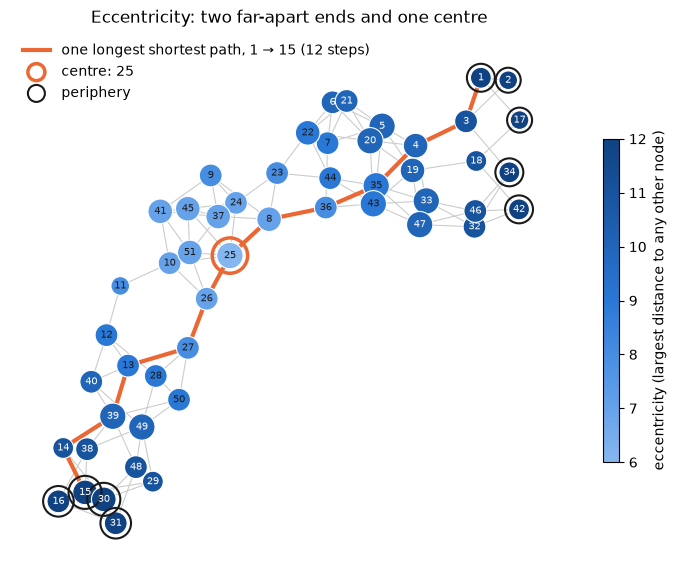

In [7]:
ACCENT = "#eb6834"  # one highlight colour for "look here" in every figure
example_path = nx.shortest_path(G, *far_pairs[0])

fig, ax = plt.subplots(figsize=(9, 7))
cbar = draw_values(ax, ecc, "Eccentricity: two far-apart ends and one centre")
cbar.set_label("eccentricity (largest distance to any other node)")
nx.draw_networkx_edges(G, pos, edgelist=list(zip(example_path, example_path[1:])), ax=ax,
                       edge_color=ACCENT, width=3)
nx.draw_networkx_nodes(G, pos, nodelist=centre, ax=ax, node_color="none", edgecolors=ACCENT, linewidths=2.5,
                       node_size=[1.8 * node_size(deg[n]) for n in centre])
nx.draw_networkx_nodes(G, pos, nodelist=periphery, ax=ax, node_color="none", edgecolors="#1a1a1a", linewidths=1.5,
                       node_size=[1.8 * node_size(deg[n]) for n in periphery])
handles = [plt.Line2D([], [], color=ACCENT, lw=3,
                      label=f"one longest shortest path, {example_path[0]} → {example_path[-1]} ({diameter} steps)"),
           ax.scatter([], [], s=150, facecolors="none", edgecolors=ACCENT, linewidths=2.5, label="centre: " + ", ".join(str(n) for n in centre)),
           ax.scatter([], [], s=150, facecolors="none", edgecolors="#1a1a1a", linewidths=1.5, label="periphery")]
ax.legend(handles=handles, loc="upper left", frameon=False)
fig.savefig(FIG / "1_eccentricity.png", dpi=150, bbox_inches="tight")
plt.show()

**Measurement:** shortest-path distances between the 9 periphery nodes and from the centre (`nx.all_pairs_shortest_path_length`). Then every shortest path (`nx.all_shortest_paths`) between the 20 periphery pairs at distance 12, and the nodes they all share. Figure: `figures/1_eccentricity.png`.

**Observation:** The periphery splits into two groups, {1, 2, 17, 34, 42} at the top right of the figure and {15, 16, 30, 31} at the bottom left. Inside a group the nodes are 1–4 steps apart; between the groups the distance is always 12. Node 25 is exactly 6 steps from all nine. All 504 shortest paths between the two ends pass through the same five nodes: 36, 8, 25, 26 and 27. In the figure, eccentricity grows along the long axis of the layout, away from 25 towards both tips.

**Interpretation:** The graph has two ends and 25 is the midpoint between them. The shortest routes from one end to the other all run through one narrow corridor, 36–8–25–26–27. This is consistent with a chain folded on itself rather than a compact ball. §2 tests the corridor with betweenness.

**Caveat:** The corridor is the shortest route, not the only one: without its five nodes the graph stays connected, so a longer detour exists. The result also concerns only the 20 most distant pairs.

In [8]:
# Node connectivity is 2, so some pairs of nodes split the graph. Which pairs, and into what?
cut_rows = []
for cut in nx.all_node_cuts(G):  # every smallest node set (here: every pair) whose removal disconnects G
    pieces = sorted(len(c) for c in nx.connected_components(G.subgraph(set(G) - cut)))
    cut_rows.append({"removed nodes": sorted(cut), "piece sizes": pieces, "smaller piece": pieces[0]})

cuts = pd.DataFrame(cut_rows).sort_values("smaller piece", ascending=False, ignore_index=True)
cuts

,removed nodes,piece sizes,smaller piece
0,"[8, 24]","[24, 25]",24
1,"[8, 23]","[23, 26]",23
2,"[23, 36]","[22, 27]",22
3,"[10, 26]","[17, 32]",17
4,"[10, 27]","[16, 33]",16
5,"[11, 26]","[16, 33]",16
6,"[11, 27]","[15, 34]",15
7,"[12, 26]","[15, 34]",15
8,"[12, 27]","[14, 35]",14
9,"[39, 49]","[8, 41]",8


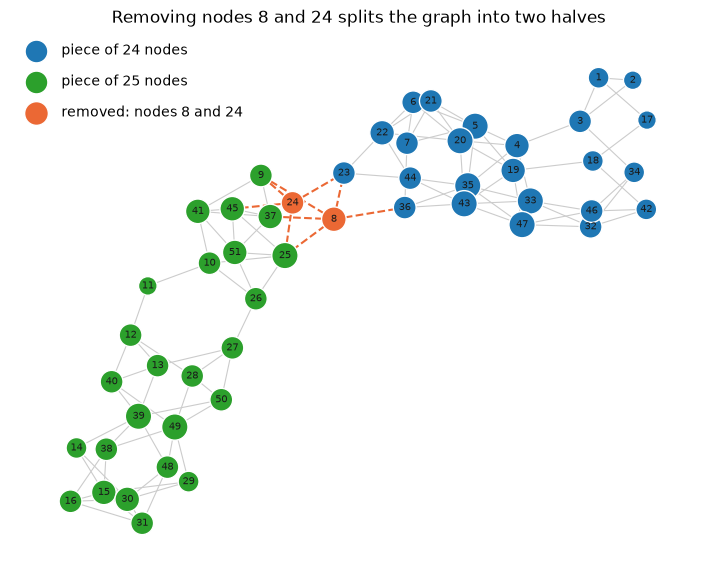

In [9]:
# The most balanced cut: colour the two pieces that are left after removing it
cut = cuts.loc[0, "removed nodes"]
rest = G.subgraph(set(G) - set(cut))
pieces = sorted(nx.connected_components(rest), key=len)
piece_colors = [plt.cm.tab10(0), plt.cm.tab10(2)]

fig, ax = plt.subplots(figsize=(9, 7))
nx.draw_networkx_edges(rest, pos, ax=ax, edge_color="0.8", width=0.8)
nx.draw_networkx_edges(G, pos, edgelist=list(G.edges(cut)), ax=ax, edge_color=ACCENT, width=1.5, style="dashed")
for color, piece in zip(piece_colors, pieces):
    members = sorted(piece)
    nx.draw_networkx_nodes(G, pos, nodelist=members, ax=ax, node_color=[color], edgecolors="white",
                           node_size=[node_size(deg[n]) for n in members], label=f"piece of {len(members)} nodes")
nx.draw_networkx_nodes(G, pos, nodelist=cut, ax=ax, node_color=ACCENT, edgecolors="white",
                       node_size=[node_size(deg[n]) for n in cut], label=f"removed: nodes {cut[0]} and {cut[1]}")
nx.draw_networkx_labels(G, pos, ax=ax, font_size=7, font_color="#1a1a1a")
ax.legend(loc="upper left", frameon=False, labelspacing=1.2)
ax.set_title(f"Removing nodes {cut[0]} and {cut[1]} splits the graph into two halves")
ax.axis("off")
fig.savefig(FIG / "1_node_cut.png", dpi=150, bbox_inches="tight")
plt.show()

**Measurement:** `nx.all_node_cuts` lists every pair of nodes whose removal disconnects the graph (pairs, because node connectivity is 2). For each pair, the table gives the sizes of the pieces left behind. Figure: `figures/1_node_cut.png` shows the most balanced cut.

**Observation:** 15 pairs split the graph. Five only cut off 1–3 nodes: the top-right tip around 1, 3, 17 and 18, or the single node 11. {39, 49} cuts off the bottom tip (8 nodes). The other nine split it into two large pieces (14 nodes or more), and they fall into two groups:
- **Upper seam:** pairs from {8, 23, 24, 36}. The most balanced, {8, 24}, separates the 24 nodes of the upper half from the other 25.
- **Lower seam:** one of {10, 11, 12} together with one of {26, 27}, cutting off the bottom-left module of 14–17 nodes.

**Interpretation:** The graph is 2-connected, but only just: it is held together at two seams, each two nodes wide. These seams lie where the longest paths funnel through the corridor above (36, 8 at one seam, 26, 27 at the other). This is consistent with three blocks in a row: the upper half, a small core around 25, and the bottom-left module. §2 (betweenness) and §6 (communities) test this independently.

**Caveat:** A node cut treats every node as equally likely to fail and ignores how much longer paths become after a split. It shows where the graph is thin, not which nodes matter most.

### 1.2 Reference models (used in §4–§8)

To decide whether a feature is specific to this graph, §4–§8 compare it with random graphs from two null models:

- **Degree-preserving randomisation** (`nx.random_reference`, repeated double-edge swaps): every node keeps its degree, but who links to whom is shuffled. It asks *"is this more than the degree sequence?"* and is the stronger null.
- **Erdős–Rényi G(N, L)** (`nx.gnm_random_graph`): only N = 51 and L = 110 are kept. It asks *"is this more than the density?"*

Each model has 200 samples with seeds 0–199. `metrics()` returns the five global numbers that later sections compare.

In [10]:
N_SAMPLES = 200

def metrics(H):
    """Global numbers we compare against the reference models in §4–§8."""
    lcc = H.subgraph(max(nx.connected_components(H), key=len))  # <d> is only defined on a connected graph
    return {
        "avg_clustering": nx.average_clustering(H),
        "avg_path_length": nx.average_shortest_path_length(lcc),
        "assortativity": nx.degree_assortativity_coefficient(H),
        "modularity": nx_comm.modularity(H, nx_comm.louvain_communities(H, seed=SEED)),
        "consecutive_id_edges": sum(abs(u - v) == 1 for u, v in H.edges()),
    }

# Degree-preserving: every node keeps its degree, links are shuffled -> "is it more than the degrees?"
# connectivity=False is much faster; the check below shows the samples stay connected anyway
refs_dp = [nx.random_reference(G, niter=10, connectivity=False, seed=i) for i in range(N_SAMPLES)]
# Erdős–Rényi G(N, L): only size and number of links are kept -> "is it more than the density?"
refs_er = [nx.gnm_random_graph(N, L, seed=i) for i in range(N_SAMPLES)]

observed = pd.Series(metrics(G))
null_dp = pd.DataFrame([metrics(R) for R in refs_dp])
null_er = pd.DataFrame([metrics(R) for R in refs_er])

In [11]:
# Sanity check of the samples: what each model keeps fixed, and how often a sample is connected
same_degrees_dp = [dict(R.degree()) == deg for R in refs_dp]
connected_dp = [nx.is_connected(R) for R in refs_dp]
connected_er = [nx.is_connected(R) for R in refs_er]

pd.DataFrame({
    "keeps fixed": ["N, L and every node's degree", "N and L"],
    "samples": [len(refs_dp), len(refs_er)],
    "seeds": [f"0–{N_SAMPLES - 1}", f"0–{N_SAMPLES - 1}"],
    "degrees identical to G": [np.mean(same_degrees_dp), np.nan],
    "share connected": [np.mean(connected_dp), np.mean(connected_er)],
}, index=["degree-preserving", "Erdős–Rényi G(N, L)"]).round(3)

,keeps fixed,samples,seeds,degrees identical to G,share connected
degree-preserving,"N, L and every node's degree",200,0–199,1.0,1.000
"Erdős–Rényi G(N, L)",N and L,200,0–199,NaN,0.595


**Measurement:** 200 samples per model (seeds 0–199). For each, whether every degree matches G and whether the sample is connected.

**Observation:** All degree-preserving samples keep every node's degree exactly, and all are connected, even though `connectivity=False` does not enforce it. Only about 60 % of the ER samples are connected; the rest have small pieces split off.

**Interpretation:** For ER, ⟨d⟩ is therefore taken on the largest component, which `metrics()` does for every graph. Clustering, assortativity and modularity are computed on the whole sample.

**Caveat:** Neither model knows about space or the node order, so any feature they fail to reproduce may come from geometry; §7 discusses this.

## 2. Important or unusual nodes

Which nodes stand out, and do different notions of "important" point to the same nodes? Four centralities from L3 answer different questions: degree (how many links), closeness (how near to all other nodes), betweenness (how many shortest paths pass through) and eigenvector (how well connected the neighbours are).

### 2.1 Four centralities

In [12]:
cent = pd.DataFrame({
    "degree": deg,
    "closeness": nx.closeness_centrality(G),      # (N − 1) / sum of distances, as in L3
    "betweenness": nx.betweenness_centrality(G),  # normalised: share of shortest paths between other node pairs
    "eigenvector": nx.eigenvector_centrality(G, max_iter=1000),  # unit norm, same ranking as L3's normalisation
}).loc[nodes]

# Top 5 per measure as "node (value)"; a stable sort keeps tied nodes in ID order
top5 = {}
for measure in cent.columns:
    best = cent[measure].sort_values(ascending=False, kind="stable").head(5)
    top5[measure] = [f"{n} ({round(v, 3):g})" for n, v in best.items()]

k_max = cent["degree"].max()
print(f"nodes tied at the maximum degree k = {k_max}:", cent.index[cent["degree"] == k_max].tolist())
pd.DataFrame(top5, index=range(1, 6)).rename_axis("rank")

nodes tied at the maximum degree k = 6: [5, 20, 25, 33, 35, 39, 43, 47, 49]


,degree,closeness,betweenness,eigenvector
rank,,,,
1,5 (6),8 (0.276),8 (0.438),43 (0.307)
2,20 (6),25 (0.27),25 (0.432),35 (0.307)
3,25 (6),36 (0.265),26 (0.381),33 (0.301)
4,33 (6),26 (0.253),36 (0.381),47 (0.301)
5,35 (6),23 (0.249),27 (0.366),20 (0.283)


In [13]:
# Do the measures rank the nodes the same way? Spearman = correlation of the ranks (1 = identical order)
cent.corr(method="spearman").round(2)

,degree,closeness,betweenness,eigenvector
degree,1.00,0.39,0.37,0.42
closeness,0.39,1.00,0.62,0.61
betweenness,0.37,0.62,1.00,0.26
eigenvector,0.42,0.61,0.26,1.00


**Measurement:** degree, closeness ((N − 1)/Σd), betweenness (normalised: the share of shortest paths between pairs of other nodes) and eigenvector centrality (unit norm) for all 51 nodes. The tables show the top 5 per measure and the Spearman rank correlations between the measures.

**Observation:** Degree hardly separates the nodes. Nine nodes tie at k = 6 (5, 20, 25, 33, 35, 39, 43, 47, 49), so its top 5 is just the first five of them in ID order. Betweenness and closeness both put 8, 25, 26 and 36 at the top. Eigenvector centrality ranks a different group first: 43, 35, 33, 47 and 20, none of which is in the betweenness top 5. The Spearman correlations are moderate at best: 0.37 between degree and betweenness and 0.26 between betweenness and eigenvector. Closeness agrees most with the others (0.62 with betweenness, 0.61 with eigenvector).

**Interpretation:** The measures do not agree on which nodes matter, so "the most important node" depends on the question asked. In a nested network (L3) the rankings would largely coincide; the weak correlations here are consistent with a graph that is not nested. Since the degrees only span 2–6, degree alone cannot tell the nodes apart; the other three measures are needed.

**Caveat:** With 51 nodes and many ties (in degree, and in betweenness and closeness, e.g. 39 and 49), rank correlations are coarse. Betweenness and closeness also count only shortest paths.

### 2.2 The corridor

§1 found that every shortest path between the two ends runs through 36, 8, 25, 26 and 27. Edge betweenness tests whether these links also carry most of the shortest paths between *all* node pairs, not just the 20 most distant ones.

In [14]:
# Which links carry the most shortest paths? Normalised: share of all node pairs whose shortest paths use the link
edge_btw = nx.edge_betweenness_centrality(G)
top_edges = sorted(edge_btw, key=edge_btw.get, reverse=True)[:8]
pd.Series({f"{u}–{v}": edge_btw[(u, v)] for u, v in top_edges}).round(3).to_frame("edge betweenness")

,edge betweenness
36–8,0.385
26–27,0.378
8–25,0.370
25–26,0.338
35–36,0.179
27–50,0.161
36–43,0.156
13–27,0.109


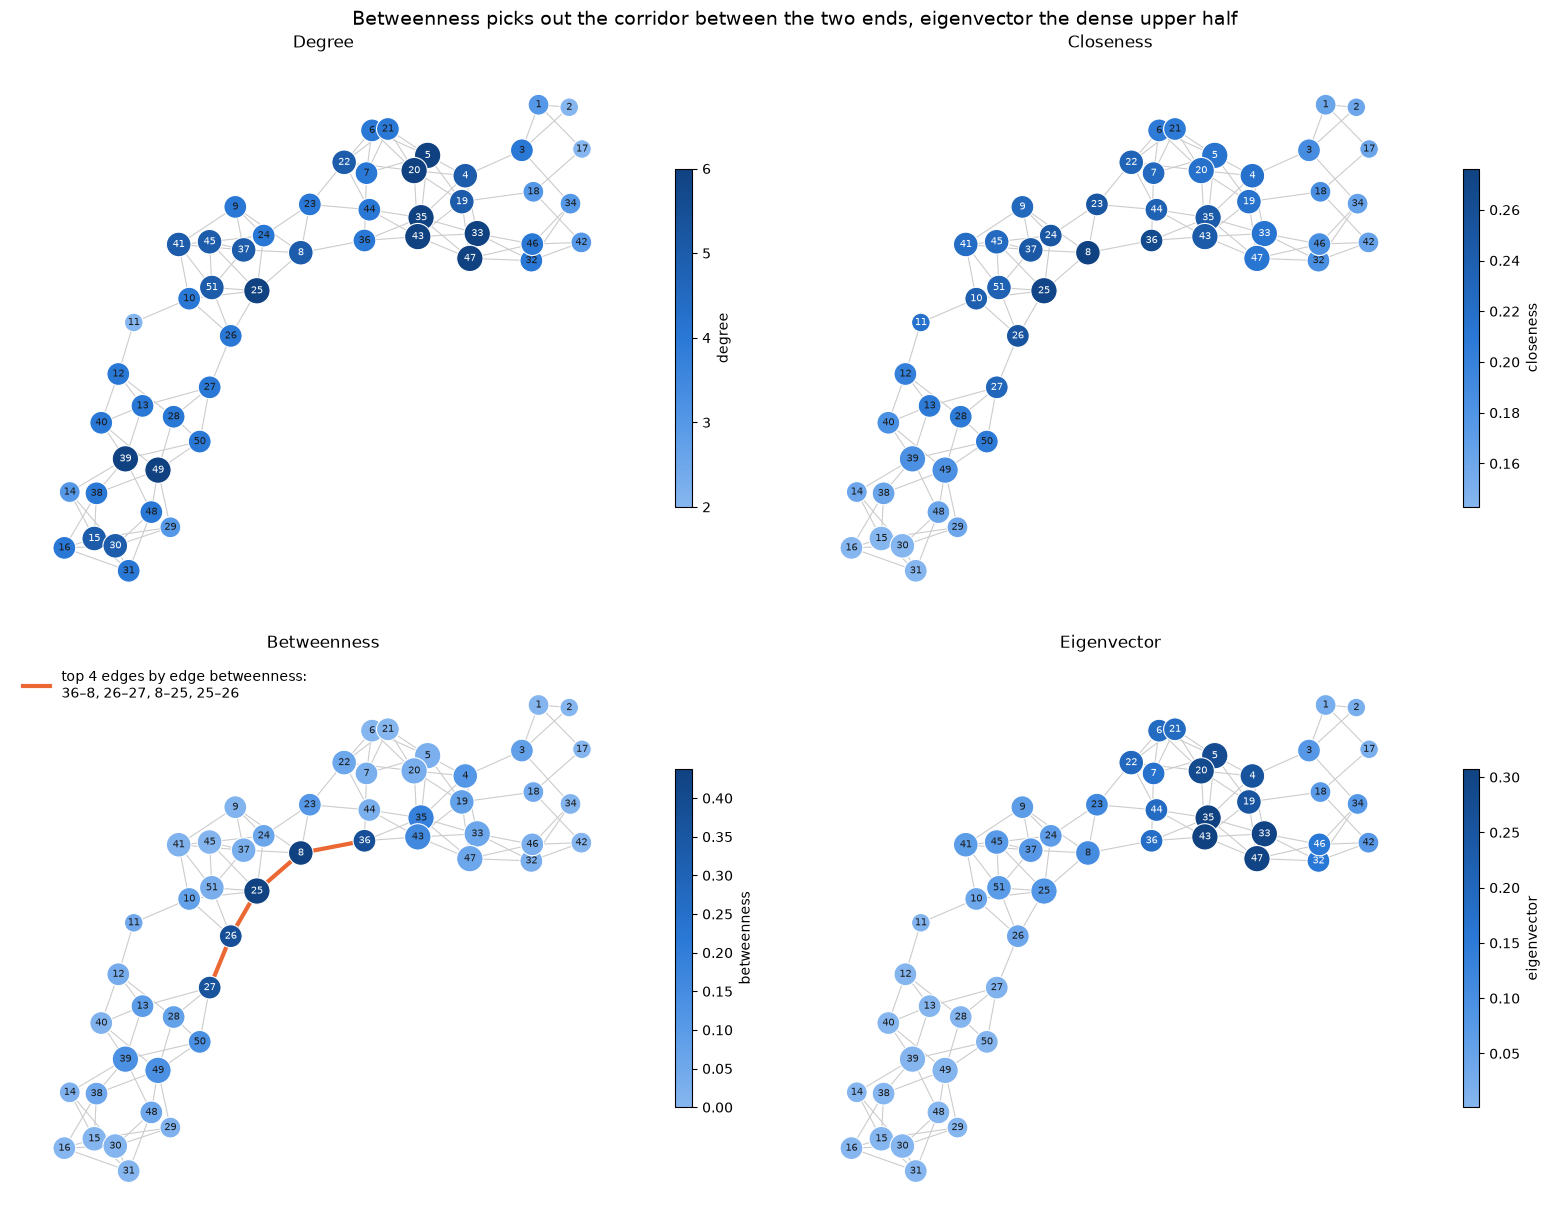

In [15]:
corridor_edges = top_edges[:4]  # the four links that stand out in the table above

fig, axes = plt.subplots(2, 2, figsize=(16, 12.5))
for ax, measure in zip(axes.flat, cent.columns):
    cbar = draw_values(ax, cent[measure].to_dict(), measure.capitalize())
    cbar.set_label(measure)
    if measure == "degree":
        cbar.set_ticks(deg_vals)

ax = axes[1, 0]  # betweenness panel: mark the links that carry the most shortest paths
nx.draw_networkx_edges(G, pos, edgelist=corridor_edges, ax=ax, edge_color=ACCENT, width=3)
corridor_label = ", ".join(f"{u}–{v}" for u, v in corridor_edges)
ax.legend(handles=[plt.Line2D([], [], color=ACCENT, lw=3, label=f"top 4 edges by edge betweenness:\n{corridor_label}")],
          loc="upper left", frameon=False)

fig.suptitle("Betweenness picks out the corridor between the two ends, eigenvector the dense upper half", fontsize=14)
fig.tight_layout()
fig.savefig(FIG / "2_centralities.png", dpi=150, bbox_inches="tight")
plt.show()

**Measurement:** edge betweenness (`nx.edge_betweenness_centrality`, normalised: the share of all node pairs' shortest paths that use the link, ties split evenly), top 8 links. Figure: `figures/2_centralities.png` shows the four centralities on the shared layout, with the top 4 links in orange on the betweenness panel.

**Observation:** Four links stand out: 36–8 (0.385), 26–27 (0.378), 8–25 (0.370) and 25–26 (0.338). The next one, 35–36, carries less than half as much (0.179). Together the four form one unbroken chain, 36–8–25–26–27, through the same five nodes found in §1, and these are also the five nodes with the highest betweenness (0.37–0.44). In the figure, betweenness is darkest along this chain. Eigenvector centrality is dark only in the dense patch around 33, 35, 43 and 47 in the upper half, and almost white across the whole bottom-left module.

**Interpretation:** On average, 34–39 % of the shortest paths between node pairs use each corridor link, so the corridor is how the upper half and the bottom-left module reach each other. The graph stays connected without it (§1), so it is a bottleneck for short routes, not for connectivity. This is consistent with a folded chain whose two halves meet at a narrow neck. Eigenvector centrality measures something different: it rewards being embedded in the densest patch, and in an elongated graph it fades with distance from that patch instead of tracking global importance.

**Caveat:** Betweenness assumes that traffic follows shortest paths and weighs all node pairs equally. Nothing is known to flow along these links, so read it as a structural bottleneck, not a transport route. The cut-off at four links comes from the gap in the table, not from a statistical test.

### 2.3 Unusual nodes

Nodes whose role differs from what their degree suggests. The table lists the corridor (top 5 by betweenness), the two k = 6 nodes with the lowest eigenvector score, and every node of the two seams from §1, with their ranks among all 51 nodes (1 = highest).

In [16]:
clust = nx.clustering(G)  # share of a node's neighbour pairs that are linked (reused in §5)
ranks = cent.rank(ascending=False, method="min").astype(int)  # 1 = highest; tied nodes share the best rank

# Seam nodes from §1: members of a 2-node cut that splits off at least a quarter of the graph
seam = set()
for cut in cuts.loc[cuts["smaller piece"] >= N / 4, "removed nodes"]:
    seam |= set(cut)
corridor = cent["betweenness"].nlargest(5).index.tolist()
low_eig_hubs = cent.loc[cent["degree"] == k_max, "eigenvector"].nsmallest(2).index.tolist()  # k = 6, yet ranked lowest

unusual = pd.DataFrame({
    "degree": cent["degree"],
    "clustering C": pd.Series(clust),
    "betweenness": cent["betweenness"],
    "betweenness rank": ranks["betweenness"],
    "eigenvector": cent["eigenvector"],
    "eigenvector rank": ranks["eigenvector"],
    "in a §1 seam": pd.Series({n: n in seam for n in nodes}),
})
picked = sorted(set(corridor) | set(low_eig_hubs) | seam)
unusual.loc[picked].sort_values("betweenness", ascending=False).round(3)

,degree,clustering C,betweenness,betweenness rank,eigenvector,eigenvector rank,in a §1 seam
8,5,0.100,0.438,1,0.106,18,True
25,6,0.267,0.432,2,0.081,19,False
26,4,0.333,0.381,3,0.041,30,True
36,4,0.000,0.381,4,0.182,13,True
27,4,0.167,0.366,5,0.011,35,True
39,6,0.067,0.136,9,0.004,42,False
49,6,0.067,0.136,9,0.004,41,False
23,4,0.167,0.109,12,0.114,17,True
10,4,0.167,0.079,15,0.040,31,True
24,4,0.167,0.060,18,0.068,27,True


**Measurement:** for the selected nodes: degree, clustering Cᵢ (`nx.clustering`), betweenness and eigenvector centrality with their ranks among all 51 nodes, and whether the node belongs to one of the nine 2-node cuts from §1 that split off at least a quarter of the graph.

**Observation:**
- **25** is the centre of the network (§1). It has the maximum degree and ranks 2nd in betweenness, but only 19th in eigenvector centrality. It is not part of any seam; it sits between the two.
- **26, 27 and 36** have only k = 4 but rank 3rd–5th in betweenness, and all three lie on a seam. **36** has C = 0: none of its four neighbours are linked to each other.
- **39 and 49** have the maximum degree, k = 6, but rank 41st–42nd of 51 in eigenvector centrality (0.004, against 0.307 for 43 and 35).
- **11** has the minimum degree, k = 2, and C = 0, and ranks only 24th in betweenness. Yet together with 26 or 27 it forms a 2-node cut that separates the bottom-left module (§1).

**Interpretation:** In this graph, importance comes from position, not from the number of links. Most of the nodes that hold the two halves together (26, 27 and 36 on the corridor, 11 on the lower seam) have average or low degree. 36 is a pure connector: it links nodes that are not directly linked to each other, rather than sitting inside a dense group. The k = 6 nodes 39 and 49 are well linked, but they sit far from the densest patch, so eigenvector centrality ignores them. This is consistent with a chain-like structure whose bottlenecks are the places where segments meet, not hubs.

**Caveat:** Which nodes count as "unusual" depends on the four measures chosen here. Ties make ranks within a tied group arbitrary (39 and 49, for example, have identical closeness and betweenness). §6 checks whether the corridor nodes also sit on community boundaries.

## 3. Degree structure

How are the 110 links spread over the 51 nodes: a few hubs and many weakly linked nodes, or roughly the same number for every node? The reference is the Erdős–Rényi model with the same N and L (§1.2), whose degrees follow approximately a Poisson distribution with the same ⟨k⟩.

In [17]:
degrees = pd.Series(deg)
mean_k = degrees.mean()
k_range = np.arange(0, 11)

# p(k) = share of nodes with degree k, next to what a Poisson distribution with the same <k> predicts (ER)
pk = pd.DataFrame({
    "nodes": degrees.value_counts().reindex(k_range, fill_value=0),
    "p(k) observed": degrees.value_counts(normalize=True).reindex(k_range, fill_value=0),
    "p(k) Poisson(⟨k⟩)": stats.poisson.pmf(k_range, mean_k),
}).rename_axis("k")

display(pd.Series({
    "mean ⟨k⟩": mean_k,
    "standard deviation": degrees.std(ddof=0),
    "min": degrees.min(),
    "max": degrees.max(),
    "variance / mean (Poisson: 1)": degrees.var(ddof=0) / mean_k,  # below 1 = more even than random
}).round(3).to_frame("value"))
pk.round(3)

,value
mean ⟨k⟩,4.314
standard deviation,1.075
min,2.000
max,6.000
variance / mean (Poisson: 1),0.268


,nodes,p(k) observed,p(k) Poisson(⟨k⟩)
k,,,
0,0,0.000,0.013
1,0,0.000,0.058
2,3,0.059,0.125
3,6,0.118,0.179
4,23,0.451,0.193
5,10,0.196,0.167
6,9,0.176,0.120
7,0,0.000,0.074
8,0,0.000,0.040


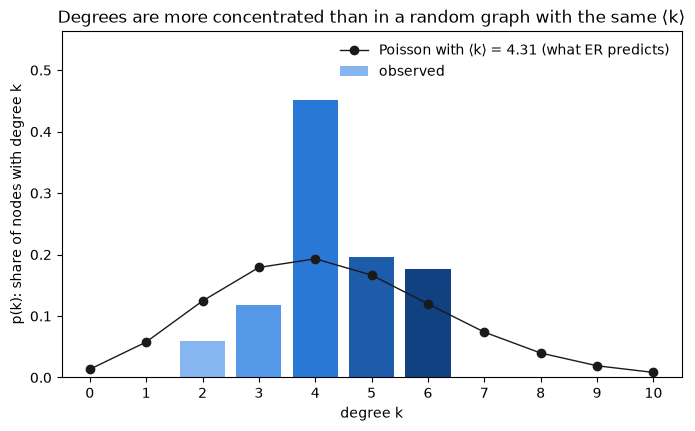

In [18]:
fig, ax = plt.subplots(figsize=(8, 4.5))
# Bars in the degree colours of §0, only for the degrees that occur
ax.bar(deg_vals, pk.loc[deg_vals, "p(k) observed"], width=0.8, color=[deg_color[k] for k in deg_vals], label="observed")
ax.plot(k_range, pk["p(k) Poisson(⟨k⟩)"], "o-", color="#1a1a1a", lw=1, ms=6, zorder=3,
        label=f"Poisson with ⟨k⟩ = {mean_k:.2f} (what ER predicts)")
ax.set_xticks(k_range)
ax.set_ylim(0, 1.25 * pk["p(k) observed"].max())  # headroom for the legend
ax.set_xlabel("degree k")
ax.set_ylabel("p(k): share of nodes with degree k")
ax.set_title("Degrees are more concentrated than in a random graph with the same ⟨k⟩")
ax.legend(frameon=False)
fig.savefig(FIG / "3_degree_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
# Are "no hubs" and "no weakly linked nodes" unusual for a random graph? The same numbers for each ER sample
er_rows = []
for R in refs_er:
    d = np.array([k for _, k in R.degree()])
    er_rows.append({"k_max": d.max(), "k_min": d.min(), "variance / mean": d.var() / d.mean()})
er_deg = pd.DataFrame(er_rows)
obs_deg = pd.Series({"k_max": degrees.max(), "k_min": degrees.min(), "variance / mean": degrees.var(ddof=0) / mean_k})

# Share of ER samples at least as narrow as G: k_max as low, k_min as high, variance / mean as low
as_narrow = pd.Series({
    "k_max": (er_deg["k_max"] <= obs_deg["k_max"]).mean(),
    "k_min": (er_deg["k_min"] >= obs_deg["k_min"]).mean(),
    "variance / mean": (er_deg["variance / mean"] <= obs_deg["variance / mean"]).mean(),
})
pd.DataFrame({
    "observed": obs_deg,
    "ER mean": er_deg.mean(),
    "ER min": er_deg.min(),
    "ER max": er_deg.max(),
    "p (share of ER samples at least as narrow)": as_narrow,
}).round(3)

,observed,ER mean,ER min,ER max,p (share of ER samples at least as narrow)
k_max,6.000,9.035,7.000,13.000,0.000
k_min,2.000,0.645,0.000,2.000,0.045
variance / mean,0.268,0.848,0.468,1.359,0.000


**Measurement:** the degree distribution p(k) with its mean, standard deviation and variance/mean (population values), against the Poisson distribution with the same ⟨k⟩ (`scipy.stats.poisson`), which an ER graph approximately follows. Then k_max, k_min and variance/mean in each of the 200 ER G(N, L) samples (seeds 0–199). Figure: `figures/3_degree_distribution.png`, with linear axes and integer k because the degrees only span 2–6.

**Observation:** All 51 nodes have between 2 and 6 links, and 45 % (23 nodes) have exactly k = 4. The standard deviation is 1.08 and variance/mean is 0.27, about a quarter of the Poisson value of 1. The Poisson curve puts 7 % of nodes at k ≤ 1 and 14 % at k = 7–10; the graph has none in either range. The ER samples agree. Their largest degree is 9.0 on average and never below 7, so none has k_max ≤ 6 (p < 1/200). Only 4.5 % of them have no node with k ≤ 1, and their lowest variance/mean is 0.47, still well above 0.27 (p < 1/200).

**Interpretation:** The degrees are more even than chance: there are no hubs and no nearly isolated nodes, and ⟨k⟩ = 4.3 describes a typical node well. This argues against a scale-free organisation (§7). It is consistent with nodes that can only make a limited number of contacts, as expected if they are structural elements packed in space (a hypothesis; the brief does not say what the nodes are). With such a narrow degree sequence, differences between nodes come from where they sit, not from how many links they have, as §2 already showed.

**Caveat:** The distribution rests on only 51 values and 5 distinct degrees, so its exact shape (e.g. the peak at k = 4) is coarse. The ER comparison shows that the degrees are more even than random, not why.

## 4. Degree correlations (assortativity)

Do nodes link to nodes of similar degree (assortative) or of very different degree (disassortative)? The test is the degree-preserving null from §1.2: it keeps every node's degree and only shuffles who links to whom, so any difference comes from the wiring, not from the degrees themselves.

In [20]:
# r = Pearson correlation of the degrees at the two ends of each link (L2), against the degree-preserving null
r_obs = observed["assortativity"]
r_null = null_dp["assortativity"]
pd.Series({
    "r observed": r_obs,
    "r degree-preserving mean": r_null.mean(),
    "r degree-preserving sd": r_null.std(),
    "z-score": (r_obs - r_null.mean()) / r_null.std(),
    "p (share of null samples with r ≥ observed)": (r_null >= r_obs).mean(),
}).round(3).to_frame("value")

,value
r observed,0.169
r degree-preserving mean,-0.035
r degree-preserving sd,0.102
z-score,1.993
p (share of null samples with r ≥ observed),0.025


In [21]:
# k_nn(k): mean neighbour degree of the nodes with degree k (L2). Rising = assortative, falling = disassortative
knn_obs = pd.Series(nx.average_neighbor_degree(G)).groupby(degrees).mean()

knn_null_rows = []
for R in refs_dp:
    knn_null_rows.append(pd.Series(nx.average_neighbor_degree(R)).groupby(pd.Series(dict(R.degree()))).mean())
knn_null = pd.DataFrame(knn_null_rows)

knn = pd.DataFrame({
    "nodes": degrees.value_counts().sort_index(),
    "k_nn observed": knn_obs,
    "k_nn null mean": knn_null.mean(),
    "k_nn null sd": knn_null.std(),
})
knn["z"] = (knn["k_nn observed"] - knn["k_nn null mean"]) / knn["k_nn null sd"]
knn.rename_axis("k").round(2)

,nodes,k_nn observed,k_nn null mean,k_nn null sd,z
k,,,,,
2,3,3.50,4.64,0.45,-2.54
3,6,4.06,4.63,0.25,-2.27
4,23,4.64,4.61,0.09,0.40
5,10,4.66,4.57,0.12,0.73
6,9,4.70,4.53,0.15,1.15


In [22]:
# Where does r come from? Count the links inside the low-degree group (the two lowest degrees) and inside
# the k = 6 group, and compare with the degree-preserving null
low_nodes = [n for n in nodes if deg[n] <= deg_vals[1]]
top_nodes = [n for n in nodes if deg[n] == k_max]

group_rows = {}
for name, members in {f"k ≤ {deg_vals[1]}": low_nodes, f"k = {k_max}": top_nodes}.items():
    links_obs = G.subgraph(members).number_of_edges()
    links_null = pd.Series([R.subgraph(members).number_of_edges() for R in refs_dp])
    group_rows[name] = {
        "nodes": members,
        "links inside": links_obs,
        "null mean": round(links_null.mean(), 2),
        "null sd": round(links_null.std(), 2),
        "p (share of null ≥ observed)": round((links_null >= links_obs).mean(), 3),
    }
    print(f"links inside {name}:", [f"{u}–{v}" for u, v in sorted(G.subgraph(members).edges())])
pd.DataFrame(group_rows).T

links inside k ≤ 3: ['1–2', '1–17', '17–18', '42–18']
links inside k = 6: ['33–35', '33–43', '33–47', '35–5', '35–47', '43–20', '43–47']


,nodes,links inside,null mean,null sd,p (share of null ≥ observed)
k ≤ 3,"[1, 2, 11, 14, 17, 18, 29, 34, 42]",4,1.1,0.91,0.02
k = 6,"[5, 20, 25, 33, 35, 39, 43, 47, 49]",7,5.87,1.87,0.355


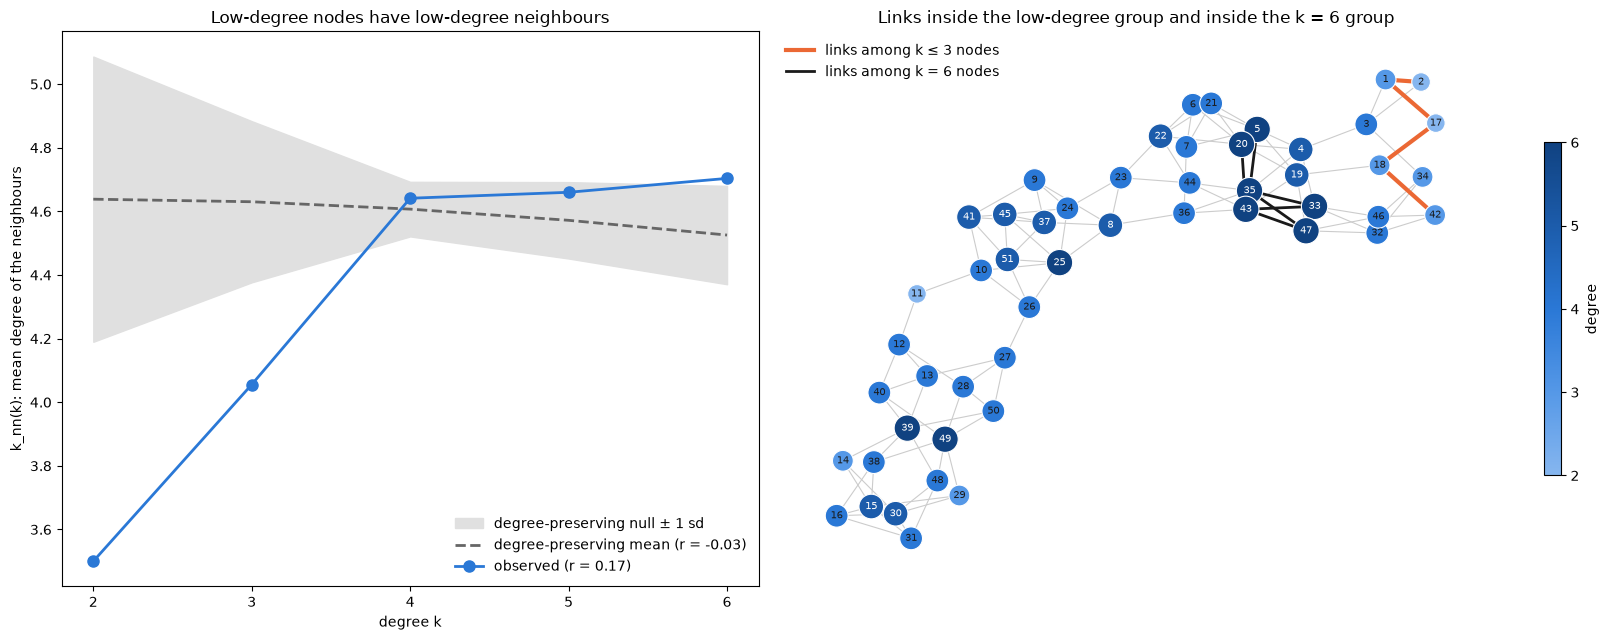

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1, 1.3]})

# Left: k_nn(k) against the degree-preserving null (mean ± 1 sd over the 200 samples)
ax1.fill_between(knn.index, knn["k_nn null mean"] - knn["k_nn null sd"], knn["k_nn null mean"] + knn["k_nn null sd"],
                 color="0.88", label="degree-preserving null ± 1 sd")
ax1.plot(knn.index, knn["k_nn null mean"], "--", color="0.4", lw=2, label=f"degree-preserving mean (r = {r_null.mean():.2f})")
ax1.plot(knn.index, knn["k_nn observed"], "o-", color="#2a78d6", lw=2, ms=8, label=f"observed (r = {r_obs:.2f})")
ax1.set_xticks(deg_vals)
ax1.set_xlabel("degree k")
ax1.set_ylabel("k_nn(k): mean degree of the neighbours")
ax1.set_title("Low-degree nodes have low-degree neighbours")
ax1.legend(frameon=False, loc="lower right")

# Right: where those links sit on the shared layout
cbar = draw_values(ax2, deg, "Links inside the low-degree group and inside the k = 6 group")
cbar.set_label("degree")
cbar.set_ticks(deg_vals)
nx.draw_networkx_edges(G, pos, edgelist=list(G.subgraph(low_nodes).edges()), ax=ax2, edge_color=ACCENT, width=3)
nx.draw_networkx_edges(G, pos, edgelist=list(G.subgraph(top_nodes).edges()), ax=ax2, edge_color="#1a1a1a", width=2)
ax2.legend(handles=[plt.Line2D([], [], color=ACCENT, lw=3, label=f"links among k ≤ {deg_vals[1]} nodes"),
                    plt.Line2D([], [], color="#1a1a1a", lw=2, label=f"links among k = {k_max} nodes")],
           loc="upper left", frameon=False)

fig.tight_layout()
fig.savefig(FIG / "4_degree_correlations.png", dpi=150, bbox_inches="tight")
plt.show()

**Measurement:** degree assortativity r (`nx.degree_assortativity_coefficient`) and k_nn(k), the mean neighbour degree of the nodes with degree k (`nx.average_neighbor_degree`, averaged per k). Both are compared with the 200 degree-preserving samples from §1.2 (seeds 0–199) via a z-score and p, the share of samples at least as extreme. Then the number of links inside the low-degree group (k ≤ 3, 9 nodes) and inside the k = 6 group (9 nodes), against the same null. Figure: `figures/4_degree_correlations.png`.

**Observation:**
- r = +0.17, against −0.03 ± 0.10 in the null (z = 2.0, p = 0.025).
- k_nn(k) rises from 3.50 at k = 2 to 4.70 at k = 6, while the null curve is flat to slightly falling (4.64 to 4.53).
- The rise comes from the low end. Nodes with k = 2 and k = 3 have neighbours of much lower degree than the null predicts (z = −2.5 and −2.3). For k = 4–6 the deviations stay within about one standard deviation (z = 0.4–1.2).
- The nine k ≤ 3 nodes share 4 links among themselves (1–2, 1–17, 17–18, 18–42), against 1.1 ± 0.9 in the null (p = 0.02). All four sit at the top-right tip, one of the two ends found in §1. The other end, {15, 16, 30, 31}, contains no k ≤ 3 node at all.
- The nine k = 6 nodes share 7 links, which is no more than the null gives (5.9 ± 1.9, p = 0.36), even though 5 of the 7 sit among 33, 35, 43 and 47.

**Interpretation:** The graph is mildly assortative, but not because high-degree nodes link to each other more than their degrees predict. The signal comes from one end of the chain, where the weakly linked nodes 1, 2, 17, 18 and 42 are linked to each other. This is consistent with a loosely packed end. It also sets the graph apart from protein *interaction* networks, which Newman's table (L2) lists as disassortative (r ≈ −0.16) because hubs link to many low-degree partners.

**Caveat:** The effect is mild and rests on few nodes: only 9 have k ≤ 3, and both p-values (0.025 and 0.02) would not pass a stricter threshold such as 0.01. With 5 distinct degrees and 110 links, r can shift noticeably when a few links change.

## 5. Local structure: triangles and clustering

Do the neighbours of a node tend to be linked to each other, and where in the graph do the triangles sit? ⟨C⟩ is the mean of the local clustering coefficients Cᵢ (the course definition), compared with both null models from §1.2.

In [24]:
# Each triangle is counted once (nx.triangles counts it at each of its 3 corners)
n_tri = sum(nx.triangles(G).values()) // 3
tri_dp = pd.Series([sum(nx.triangles(R).values()) // 3 for R in refs_dp])
tri_er = pd.Series([sum(nx.triangles(R).values()) // 3 for R in refs_er])
print("transitivity (side check: 3 × triangles / connected triples):", round(nx.transitivity(G), 3))

clustering_rows = {}
for name, obs, dp, er in [("average clustering ⟨C⟩", observed["avg_clustering"], null_dp["avg_clustering"], null_er["avg_clustering"]),
                          ("triangles", n_tri, tri_dp, tri_er)]:
    clustering_rows[name] = {
        "observed": obs,
        "degree-preserving mean": dp.mean(),
        "degree-preserving sd": dp.std(),
        "degree-preserving max": dp.max(),
        "ER mean": er.mean(),
        "ER sd": er.std(),
        "ER max": er.max(),
        "observed / degree-preserving mean": obs / dp.mean(),
    }
pd.DataFrame(clustering_rows).round(3)

transitivity (side check: 3 × triangles / connected triples): 0.244


,average clustering ⟨C⟩,triangles
observed,0.238,32.000
degree-preserving mean,0.063,8.060
degree-preserving sd,0.025,2.788
degree-preserving max,0.139,16.000
ER mean,0.081,12.940
ER sd,0.026,3.392
ER max,0.154,23.000
observed / degree-preserving mean,3.793,3.970


In [25]:
# Where are the triangles? Maximal cliques, nodes without any triangle, and links that are in no triangle
cliques = sorted(nx.find_cliques(G), key=len, reverse=True)  # maximal cliques, largest first
print("maximal clique sizes (size: count):", pd.Series([len(c) for c in cliques]).value_counts().sort_index().to_dict())
print("largest clique:", sorted(cliques[0]))
print("nodes with C = 0:", [n for n in nodes if clust[n] == 0])

triangles = sorted(tuple(sorted(c)) for c in nx.enumerate_all_cliques(G) if len(c) == 3)
print(f"the {len(triangles)} triangles:", ", ".join("–".join(map(str, t)) for t in triangles))

# Number of triangles a link is part of = number of common neighbours of its two ends
link_tri = {(u, v): len(set(G[u]) & set(G[v])) for u, v in G.edges()}
print(f"links in at least one triangle: {sum(t > 0 for t in link_tri.values())} of {L}")
pd.Series({f"{u}–{v}": link_tri[(u, v)] for u, v in corridor_edges}).to_frame("triangles on the corridor links (§2)")

maximal clique sizes (size: count): {2: 40, 3: 28, 4: 1}
largest clique: [37, 41, 45, 51]
nodes with C = 0: [11, 14, 17, 18, 29, 34, 36, 42]
the 32 triangles: 1–2–3, 4–5–35, 4–33–35, 5–6–7, 5–7–21, 6–20–22, 8–9–37, 9–37–41, 10–25–26, 12–13–40, 13–39–40, 15–16–31, 15–16–38, 16–30–31, 19–20–43, 19–43–47, 20–21–22, 22–23–44, 24–25–45, 25–26–51, 25–45–51, 27–28–50, 28–49–50, 30–31–48, 32–33–47, 33–35–47, 33–43–47, 33–46–47, 37–41–45, 37–41–51, 37–45–51, 41–45–51
links in at least one triangle: 70 of 110


,triangles on the corridor links (§2)
36–8,0
26–27,0
8–25,0
25–26,2


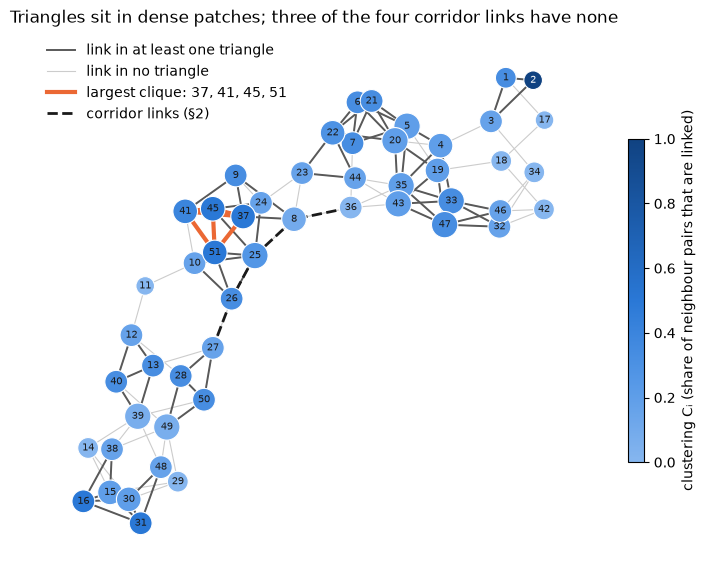

In [26]:
clique = sorted(cliques[0])
tri_links = [e for e, t in link_tri.items() if t > 0]

fig, ax = plt.subplots(figsize=(9, 7))
cbar = draw_values(ax, clust, "Triangles sit in dense patches; three of the four corridor links have none")
cbar.set_label("clustering Cᵢ (share of neighbour pairs that are linked)")
nx.draw_networkx_edges(G, pos, edgelist=tri_links, ax=ax, edge_color="0.35", width=1.4)
nx.draw_networkx_edges(G, pos, edgelist=list(G.subgraph(clique).edges()), ax=ax, edge_color=ACCENT, width=3)
nx.draw_networkx_edges(G, pos, edgelist=corridor_edges, ax=ax, edge_color="#1a1a1a", width=2, style="dashed")
handles = [plt.Line2D([], [], color="0.35", lw=1.4, label="link in at least one triangle"),
           plt.Line2D([], [], color="0.8", lw=0.8, label="link in no triangle"),
           plt.Line2D([], [], color=ACCENT, lw=3, label="largest clique: " + ", ".join(map(str, clique))),
           plt.Line2D([], [], color="#1a1a1a", lw=2, ls="--", label="corridor links (§2)")]
ax.legend(handles=handles, loc="upper left", frameon=False)
fig.savefig(FIG / "5_clustering.png", dpi=150, bbox_inches="tight")
plt.show()

**Measurement:** local clustering Cᵢ (`nx.clustering`, from §2), ⟨C⟩ as their mean, the triangle count (`nx.triangles`), transitivity as a side check, maximal cliques (`nx.find_cliques`), and for each link the number of triangles it is part of. ⟨C⟩ and the triangle count are compared with the 200 degree-preserving and 200 ER samples from §1.2 (seeds 0–199). Figure: `figures/5_clustering.png`.

**Observation:**
- ⟨C⟩ = 0.238 (transitivity 0.244). That is 3.8× the degree-preserving mean of 0.063 ± 0.025 and about 3× the ER mean of 0.081 ± 0.026. No sample of either null reaches it (maximum 0.139 and 0.154), so p < 1/200 for both.
- The graph has 32 triangles, against 8.1 ± 2.8 (maximum 16) in the degree-preserving null and 12.9 ± 3.4 (maximum 23) in ER.
- The triangles do not merge into large cliques. The only clique bigger than a triangle is {37, 41, 45, 51} (4 nodes); the other 28 triangles stand on their own. Together with the triangles next to it (8–9–37, 9–37–41, 24–25–45, 25–26–51, 25–45–51), the clique forms a dense patch beside the centre 25. Other dense spots are 5–6–7, 5–7–21 and 20–21–22 at the top, 32–33–47, 33–35–47, 33–43–47 and 33–46–47 around 33 and 47, and 15–16–31, 15–16–38, 16–30–31 and 30–31–48 at the bottom-left end.
- 70 of the 110 links lie in at least one triangle. Three of the four corridor links (36–8, 26–27, 8–25) lie in none; only 25–26 does (2 triangles).
- Eight nodes have C = 0: 11, 14, 17, 18, 29, 34, 36, 42. They include the connector 36 and the seam node 11 from §2, and the top-right nodes 17, 18, 34 and 42 (§4).

**Interpretation:** The clustering is real and not a by-product of the degrees: shuffling the links while keeping every degree removes about three quarters of the triangles. The triangles concentrate in a few dense patches, while the links that hold the graph together (the corridor, and the seam around 11) have few or none. This is consistent with tightly packed local regions joined by sparse connections, and it fits the elongated shape from §1: a node's neighbours are often linked to each other, but the regions they form are strung out in a row. §6 checks whether these patches coincide with communities, and §7 compares ⟨C⟩ with a ring lattice.

**Caveat:** Cᵢ is very coarse for low-degree nodes: a k = 2 node has C = 0 or 1, which is why node 2 (C = 1) is the darkest node in the figure. ⟨C⟩ weighs such nodes as much as nodes with six links. Transitivity does not, and it gives almost the same value (0.244), so the conclusion does not depend on this choice.

## 6. Communities and mesoscopic structure

Does the graph split into groups that are densely linked inside and sparsely linked to each other, and how convincing is each group? Two modularity-based methods from L5: greedy agglomeration (CNM, deterministic) and Louvain (`seed=SEED`). Q is compared with the null models from §1.2, and Louvain is re-run with 100 seeds to see which groups are stable.

### 6.1 Partitions and modularity

In [27]:
# Sorted by smallest node ID, so that matching communities get the same colour in both partitions
partitions = {
    "greedy (CNM)": sorted(nx_comm.greedy_modularity_communities(G), key=min),
    f"Louvain (seed {SEED})": sorted(nx_comm.louvain_communities(G, seed=SEED), key=min),
}
louvain = partitions[f"Louvain (seed {SEED})"]
q_null = null_dp["modularity"]  # Louvain Q of each degree-preserving sample (§1.2)

q_rows = {}
for name, communities in partitions.items():
    q = nx_comm.modularity(G, communities)
    q_rows[name] = {"communities": len(communities), "Q": q, "z vs degree-preserving": (q - q_null.mean()) / q_null.std()}
for name, null in [("degree-preserving null (200 samples)", null_dp), ("ER null (200 samples)", null_er)]:
    q_rows[name] = {"Q": null["modularity"].mean(), "Q sd": null["modularity"].std(), "Q max": null["modularity"].max()}

# A ring lattice has no groups at all, but it is a long chain closed into a loop: how high can Q get from shape alone?
lattice = nx.watts_strogatz_graph(N, 4, 0)  # p = 0: each node linked to its 2 nearest neighbours on each side
lattice_communities = nx_comm.louvain_communities(lattice, seed=SEED)
q_rows["ring lattice (N = 51, k = 4)"] = {"communities": len(lattice_communities),
                                          "Q": nx_comm.modularity(lattice, lattice_communities)}

q_table = pd.DataFrame(q_rows).T.round(3)
q_table["communities"] = q_table["communities"].astype("Int64")
q_table

,communities,Q,z vs degree-preserving,Q sd,Q max
greedy (CNM),4,0.593,9.457,NaN,NaN
Louvain (seed 42),5,0.613,10.483,NaN,NaN
degree-preserving null (200 samples),<NA>,0.410,NaN,0.019,0.468
ER null (200 samples),<NA>,0.398,NaN,0.019,0.446
"ring lattice (N = 51, k = 4)",7,0.647,NaN,NaN,NaN


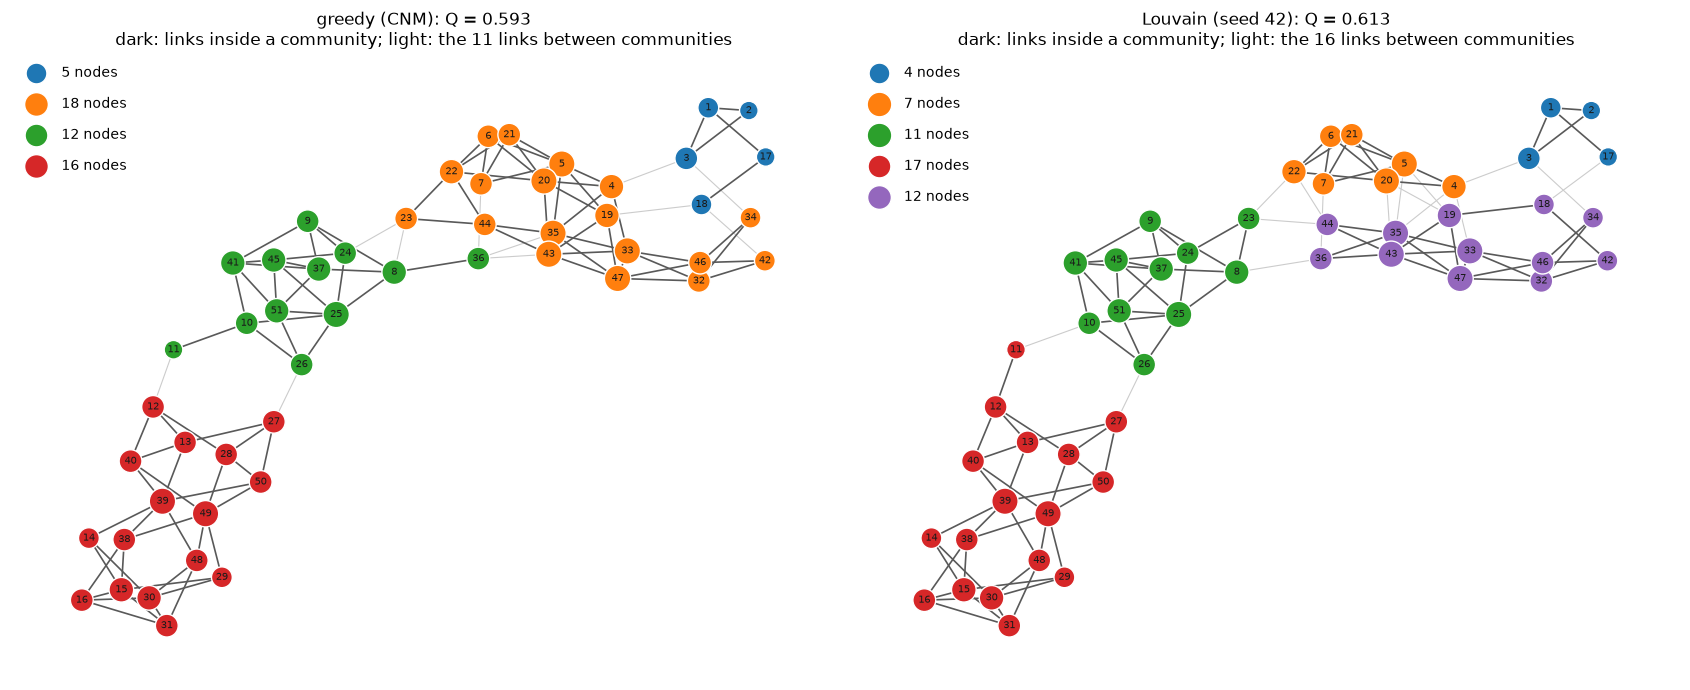

In [28]:
membership = {}  # node -> community index, for each partition
for name, communities in partitions.items():
    membership[name] = {}
    for i, c in enumerate(communities):
        for n in c:
            membership[name][n] = i

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, (name, communities) in zip(axes, partitions.items()):
    member = membership[name]
    between = [(u, v) for u, v in G.edges() if member[u] != member[v]]
    inside = [(u, v) for u, v in G.edges() if member[u] == member[v]]
    nx.draw_networkx_edges(G, pos, edgelist=between, ax=ax, edge_color="0.8", width=0.8)
    nx.draw_networkx_edges(G, pos, edgelist=inside, ax=ax, edge_color="0.35", width=1.2)
    for i, c in enumerate(communities):
        nx.draw_networkx_nodes(G, pos, nodelist=sorted(c), ax=ax, node_color=[plt.cm.tab10(i)], edgecolors="white",
                               node_size=[node_size(deg[n]) for n in sorted(c)], label=f"{len(c)} nodes")
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=7, font_color="#1a1a1a")
    ax.set_title(f"{name}: Q = {nx_comm.modularity(G, communities):.3f}\n"
                 f"dark: links inside a community; light: the {len(between)} links between communities")
    ax.legend(loc="upper left", frameon=False, labelspacing=1.2)
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIG / "6_communities.png", dpi=150, bbox_inches="tight")
plt.show()

**Measurement:** greedy modularity maximisation (`nx_comm.greedy_modularity_communities`, CNM) and Louvain (`nx_comm.louvain_communities`, seed 42), scored with modularity Q (`nx_comm.modularity`). Q is compared with the Louvain Q of the 200 degree-preserving and 200 ER samples from §1.2 (seeds 0–199), and with a ring lattice of the same size and k = 4 ≈ ⟨k⟩. Figure: `figures/6_communities.png`.

**Observation:** Greedy finds 4 communities (Q = 0.593), Louvain 5 (Q = 0.613). Both are far above the degree-preserving null, 0.410 ± 0.019 (z = 9.5 and 10.5; the highest of the 200 samples reaches 0.468), and the ER null, 0.398 ± 0.019. The two partitions agree on three groups:
- the **bottom-left module** (red); node 11 joins it in Louvain only,
- the **core** around 25 (green); it contains 11 and 36 in greedy and 23 in Louvain,
- the **top-right tip** around 1, 2, 3 and 17 (blue); greedy adds 18.

They differ in the **upper half**: greedy keeps it as one community of 18 nodes, while Louvain splits it into {4–7, 20–22} and a group around 33, 35, 43 and 47. A ring lattice, which has no groups at all, reaches Q = 0.647, higher than either partition.

**Interpretation:** The graph has far more community structure than its degrees alone produce, and the two methods agree on where most of it is. A high Q is not proof of separate groups here, though: the ring lattice scores even higher, because any long, thin graph can be cut into consecutive pieces with few links between them. Part of the high Q therefore reflects the elongated shape from §1. The tests below (links leaving each community, stability, triangles) decide which communities are convincing.

**Caveat:** Both methods maximise modularity, so they share its blind spots: the resolution limit and many near-optimal partitions (§6.2–6.3). The null Q values come from Louvain only, so greedy's z-score compares two slightly different algorithms.

### 6.2 How convincing is each community?

For each community: its members as runs of consecutive node IDs, the links inside and leaving, the nodes with at least as many links outside as inside (k_int ≤ k_ext), and the two L5 tests. A community is *strong* if every node has k_int > k_ext, and *weak* if its members have more link ends inside than outside (Σk_int > Σk_ext).

In [29]:
def id_runs(nodes):
    """Split node IDs into runs of consecutive integers, e.g. {1, 2, 3, 7} -> [[1, 2, 3], [7]]."""
    runs = []
    for n in sorted(nodes):
        if runs and n == runs[-1][-1] + 1:
            runs[-1].append(n)
        else:
            runs.append([n])
    return runs

# Readable community names for the tables, e.g. "11–16, 27–31, 38–40, 48–50" (used again in §8)
labels = {}
for communities in partitions.values():
    for c in communities:
        labels[frozenset(c)] = ", ".join(f"{r[0]}–{r[-1]}" if len(r) > 1 else str(r[0]) for r in id_runs(c))

In [30]:
community_rows = []
for name, communities in partitions.items():
    member = membership[name]
    for i, c in enumerate(communities):
        k_int, k_ext = {}, {}
        for n in c:
            k_int[n] = sum(member[m] == i for m in G[n])  # links of n that stay inside its community
            k_ext[n] = deg[n] - k_int[n]
        inside = G.subgraph(c).number_of_edges()
        community_rows.append({
            "partition": name,
            "members (ID runs)": labels[frozenset(c)],
            "size": len(c),
            "links inside": inside,
            "links leaving": sum(k_ext.values()),
            "nodes with k_int ≤ k_ext": [n for n in sorted(c) if k_int[n] <= k_ext[n]],
            "strong": all(k_int[n] > k_ext[n] for n in c),
            "weak": 2 * inside > sum(k_ext.values()),
            "total degree K": sum(deg[n] for n in c),
        })
print(f"resolution limit (L5): modularity cannot reliably resolve communities with K below √(2L) = {np.sqrt(2 * L):.1f}")
pd.DataFrame(community_rows).set_index(["partition", "members (ID runs)"])

resolution limit (L5): modularity cannot reliably resolve communities with K below √(2L) = 14.8


size  links inside  \
partition         members (ID runs)                                     
greedy (CNM)      1–3, 17–18                          5             5   
                  4–7, 19–23, 32–35, 42–44, 46–47    18            38   
                  8–11, 24–26, 36–37, 41, 45, 51     12            23   
                  12–16, 27–31, 38–40, 48–50         16            33   
Louvain (seed 42) 1–3, 17                             4             4   
                  4–7, 20–22                          7            12   
                  8–10, 23–26, 37, 41, 45, 51        11            23   
                  11–16, 27–31, 38–40, 48–50         17            34   
                  18–19, 32–36, 42–44, 46–47         12            21   

                                                   links leaving  \
partition         members (ID runs)                                
greedy (CNM)      1–3, 17–18                                   4   
                  4–7, 19–23, 32–35, 42–44, 46–47              9   
                  8–11, 24–26, 36–37, 41, 45, 51               7   
                  12–16, 27–31, 38–40, 48–50                   2   
Louvain (seed 42) 1–3, 17                                      3   
                  4–7, 20–22                                  10   
                  8–10, 23–26, 37, 41, 45, 51                  5   
                  11–16, 27–31, 38–40, 48–50                   2   
                  18–19, 32–36, 42–44, 46–47                  12   

                                                  nodes with k_int ≤ k_ext  \
partition         members (ID runs)                                          
greedy (CNM)      1–3, 17–18                                       [3, 18]   
                  4–7, 19–23, 32–35, 42–44, 46–47                     [23]   
                  8–11, 24–26, 36–37, 41, 45, 51                  [11, 36]   
                  12–16, 27–31, 38–40, 48–50                            []   
Louvain (seed 42) 1–3, 17                                          [3, 17]   
                  4–7, 20–22                                           [4]   
                  8–10, 23–26, 37, 41, 45, 51                         [23]   
                  11–16, 27–31, 38–40, 48–50                          [11]   
                  18–19, 32–36, 42–44, 46–47                      [36, 44]   

                                                   strong  weak  \
partition         members (ID runs)                               
greedy (CNM)      1–3, 17–18                        False  True   
                  4–7, 19–23, 32–35, 42–44, 46–47   False  True   
                  8–11, 24–26, 36–37, 41, 45, 51    False  True   
                  12–16, 27–31, 38–40, 48–50         True  True   
Louvain (seed 42) 1–3, 17                           False  True   
                  4–7, 20–22                        False  True   
                  8–10, 23–26, 37, 41, 45, 51       False  True   
                  11–16, 27–31, 38–40, 48–50        False  True   
                  18–19, 32–36, 42–44, 46–47        False  True   

                                                   total degree K  
partition         members (ID runs)                                
greedy (CNM)      1–3, 17–18                                   14  
                  4–7, 19–23, 32–35, 42–44, 46–47              85  
                  8–11, 24–26, 36–37, 41, 45, 51               53  
                  12–16, 27–31, 38–40, 48–50                   68  
Louvain (seed 42) 1–3, 17                                      11  
                  4–7, 20–22                                   34  
                  8–10, 23–26, 37, 41, 45, 51                  51  
                  11–16, 27–31, 38–40, 48–50                   70  
                  18–19, 32–36, 42–44, 46–47                   54

**Measurement:** for every community of both partitions: links inside and leaving, nodes with k_int ≤ k_ext, the strong and weak tests from L5, and the total degree K against the resolution limit √(2L) = 14.8.

**Observation:**
- The **bottom-left module** is the most clearly separated community. In greedy it has 16 nodes (12–16, 27–31, 38–40, 48–50), 33 links inside and only 2 leaving: 11–12 and 26–27, the light links in the figure. It is the only *strong* community in either partition: every one of its nodes has more links inside than outside. Louvain adds node 11 (17 nodes, 34 links inside, still only 2 leaving: 10–11 and 26–27). Node 11 has one link on each side, so with it the module is no longer strong.
- All nine communities are *weak*: their members have more link ends inside than outside. Every community except greedy's module has at least one node with k_int ≤ k_ext; across both partitions these are 3, 4, 11, 17, 18, 23, 36 and 44.
- Half of these borderline nodes (4, 23, 36, 44) lie in the **upper half**, where the two partitions disagree, or on its edge (23 and 36 are seam nodes from §1). Louvain's group around 33–47 has 12 links leaving for 21 inside, and {4–7, 20–22} has 10 leaving for 12 inside. The core has 5 leaving for 23 inside.
- The **top-right tip** {1, 2, 3, 17} (Louvain) has total degree K = 11. Greedy's version, which includes 18, has K = 14. Both are below √(2L) = 14.8.

**Interpretation:** Only the bottom-left module is convincing on every test. It is attached to the rest by two links, and its single borderline node, 11, is the seam node found in §1 and §2. The core around 25 is also well separated. The upper half is a dense region without a clear internal boundary: each way of splitting it leaves many links between the parts. The tip community lies below the resolution limit, so modularity cannot be trusted to say whether it is a separate group or part of its neighbour.

**Caveat:** k_int and k_ext depend on the partition, so a node is "borderline" only relative to these two partitions. With 2–6 links per node, a single link decides whether k_int > k_ext.

### 6.3 Stability across Louvain seeds

Louvain depends on the order in which it visits the nodes. Re-running it with seeds 0–99 separates groups that are a property of the graph from groups that are a choice of the algorithm.

In [31]:
louvain_runs = [nx_comm.louvain_communities(G, seed=s) for s in range(100)]
run_q = [nx_comm.modularity(G, p) for p in louvain_runs]
distinct = set()
for p in louvain_runs:
    distinct.add(frozenset(frozenset(c) for c in p))
print(f"seeds 0–99: {len(distinct)} distinct partitions with {sorted({len(p) for p in louvain_runs})} communities, "
      f"Q from {min(run_q):.3f} to {max(run_q):.3f}")

# How often does each community of the seed-42 partition come out again: unchanged, or at least with all members together?
stability_rows = {}
for c in louvain:
    unchanged, together = 0, 0
    for p in louvain_runs:
        unchanged += c in p
        together += any(c <= d for d in p)
    stability_rows[labels[frozenset(c)]] = {"size": len(c), "unchanged (of 100 runs)": unchanged,
                                            "members kept together (of 100 runs)": together}
pd.DataFrame(stability_rows).T.rename_axis(f"Louvain (seed {SEED}) community")

seeds 0–99: 13 distinct partitions with [4, 5] communities, Q from 0.604 to 0.625


,size,unchanged (of 100 runs),members kept together (of 100 runs)
Louvain (seed 42) community,,,
"1–3, 17",4,34,99
"4–7, 20–22",7,20,79
"8–10, 23–26, 37, 41, 45, 51",11,79,79
"11–16, 27–31, 38–40, 48–50",17,100,100
"18–19, 32–36, 42–44, 46–47",12,20,36


In [32]:
# Which nodes share a community in every one of the 100 runs? Those groups are stable; all other nodes move
run_member = []
for p in louvain_runs:
    m = {}
    for i, c in enumerate(p):
        for n in c:
            m[n] = i
    run_member.append(m)

always = nx.Graph()  # link = "in the same community in all 100 runs"
always.add_nodes_from(nodes)
for u, v in combinations(nodes, 2):
    if all(m[u] == m[v] for m in run_member):
        always.add_edge(u, v)
stable_groups = sorted((c for c in nx.connected_components(always) if len(c) > 1), key=min)
moving = sorted(n for n in nodes if always.degree(n) == 0)

for c in stable_groups:
    print(f"stable group of {len(c):>2} nodes:", sorted(c))
print("nodes that change community between runs:", moving)

stable group of  3 nodes: [1, 2, 3]
stable group of  6 nodes: [5, 6, 7, 20, 21, 22]
stable group of 10 nodes: [8, 9, 10, 24, 25, 26, 37, 41, 45, 51]
stable group of 17 nodes: [11, 12, 13, 14, 15, 16, 27, 28, 29, 30, 31, 38, 39, 40, 48, 49, 50]
stable group of  4 nodes: [32, 34, 42, 46]
stable group of  2 nodes: [33, 47]
nodes that change community between runs: [4, 17, 18, 19, 23, 35, 36, 43, 44]


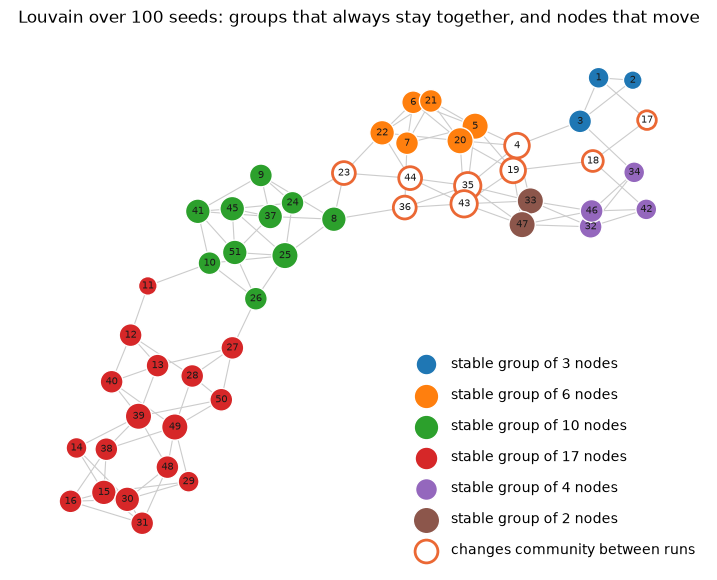

In [33]:
fig, ax = plt.subplots(figsize=(9, 7))
nx.draw_networkx_edges(G, pos, ax=ax, edge_color="0.8", width=0.8)
for i, c in enumerate(stable_groups):
    nx.draw_networkx_nodes(G, pos, nodelist=sorted(c), ax=ax, node_color=[plt.cm.tab10(i)], edgecolors="white",
                           node_size=[node_size(deg[n]) for n in sorted(c)], label=f"stable group of {len(c)} nodes")
nx.draw_networkx_nodes(G, pos, nodelist=moving, ax=ax, node_color="white", edgecolors=ACCENT, linewidths=2,
                       node_size=[node_size(deg[n]) for n in moving], label="changes community between runs")
nx.draw_networkx_labels(G, pos, ax=ax, font_size=7, font_color="#1a1a1a")
ax.legend(loc="lower right", frameon=False, labelspacing=1.2)  # the empty corner
ax.set_title("Louvain over 100 seeds: groups that always stay together, and nodes that move")
ax.axis("off")
fig.savefig(FIG / "6_stability.png", dpi=150, bbox_inches="tight")
plt.show()

**Measurement:** Louvain with seeds 0–99. For each seed-42 community: how often it comes out unchanged, and how often all its members land in one community. Then the groups of nodes that share a community in all 100 runs, and the nodes outside any such group. Figure: `figures/6_stability.png`.

**Observation:**
- The 100 runs give 13 distinct partitions with 4 or 5 communities, and Q between 0.604 and 0.625.
- Only the bottom-left module (11–16, 27–31, 38–40, 48–50) comes out unchanged in all 100 runs.
- The core (8–10, 23–26, 37, 41, 45, 51) comes out unchanged in 79 runs. Without node 23, its other ten nodes stay together in all 100.
- Four more groups are stable: {1, 2, 3}, {5, 6, 7, 20, 21, 22}, {32, 34, 42, 46} and {33, 47}.
- Nine nodes change community between runs: 4, 17, 18, 19, 23, 35, 36, 43 and 44. All lie in the upper half, on its edge (23, 36) or at the top-right tip (17, 18). They include every borderline node from §6.2 except 3 and 11.

**Interpretation:** The module and the core are properties of the graph; the boundaries inside the upper half are choices of the algorithm. The nine moving nodes sit between the stable pockets of the upper half and the tip, among them the connector 36 (§2) and the high-degree nodes 35 and 43. The upper half is therefore best described as one dense region with a few stable pockets, not as two or three separate communities.

**Caveat:** Stability across seeds shows that a group is robust to Louvain's random visiting order, not that the group is real. A method that does not maximise modularity could cut the graph differently.

### 6.4 Communities, triangles and the corridor

Do the communities agree with the dense patches of §5 and with the corridor of §2?

In [34]:
member = membership[f"Louvain (seed {SEED})"]
crossing = [t for t in triangles if not member[t[0]] == member[t[1]] == member[t[2]]]
print(f"triangles inside one community: {len(triangles) - len(crossing)} of {len(triangles)}; "
      "the others:", ", ".join("–".join(map(str, t)) for t in crossing))
print("corridor links (§2) between communities:", [f"{u}–{v}" for u, v in corridor_edges if member[u] != member[v]])

# How many communities does each corridor or seam node touch (its own plus those of its neighbours)?
touch_rows = {}
for n in sorted(seam | set(corridor)):
    touched = {member[m] for m in G[n]} | {member[n]}
    touch_rows[n] = {"own community": labels[frozenset(louvain[member[n]])], "communities touched": len(touched)}
pd.DataFrame(touch_rows).T.rename_axis("node")

triangles inside one community: 28 of 32; the others: 4–5–35, 4–33–35, 19–20–43, 22–23–44
corridor links (§2) between communities: ['36–8', '26–27']


,own community,communities touched
node,,
8,"8–10, 23–26, 37, 41, 45, 51",2
10,"8–10, 23–26, 37, 41, 45, 51",2
11,"11–16, 27–31, 38–40, 48–50",2
12,"11–16, 27–31, 38–40, 48–50",1
23,"8–10, 23–26, 37, 41, 45, 51",3
24,"8–10, 23–26, 37, 41, 45, 51",1
25,"8–10, 23–26, 37, 41, 45, 51",1
26,"8–10, 23–26, 37, 41, 45, 51",2
27,"11–16, 27–31, 38–40, 48–50",2


**Measurement:** for the Louvain (seed 42) partition: the triangles from §5 whose three nodes lie in one community, the corridor links from §2 that join two communities, and for each corridor or seam node the number of communities among itself and its neighbours.

**Observation:** 28 of the 32 triangles lie inside one community. The other four (4–5–35, 4–33–35, 19–20–43, 22–23–44) all sit in the upper half, and each contains moving nodes from §6.3 (4, 19, 23, 35, 43, 44). Two of the four corridor links join communities: 36–8 (upper half to core) and 26–27 (core to bottom-left module). The other two, 8–25 and 25–26, lie inside the core. Nodes 23 and 36 touch three communities each; every other corridor or seam node touches one or two.

**Interpretation:** The communities agree with the earlier sections. The dense patches of §5 sit inside communities, and the triangles that cross a boundary are exactly where §6.3 found moving nodes. The corridor of §2 runs from the upper half through the core into the module and crosses a community boundary at each end. This supports the picture from §1 of three blocks in a row (upper half, core around 25, bottom-left module), with the corridor as the route that all the longest shortest paths take.

**Caveat:** These checks use one partition (Louvain, seed 42). In greedy, 36 belongs to the core, so the upper boundary sits on 36's links to the upper half instead of on 36–8. The lower boundary at 26–27 is the same in both partitions.

## 7. Comparison with random, small-world and scale-free models

Which textbook model, if any, does the graph resemble? §1.2–§6 compared single numbers with the null models. This section puts them side by side and adds the Watts–Strogatz model, which moves from a ring lattice to a random graph as more links are rewired (L4).

### 7.1 Global numbers against the null models

In [35]:
# One table for all global numbers: observed vs. both nulls (200 samples each, seeds 0–199) and the ring lattice (§6)
comparison = pd.DataFrame({
    "observed": observed,
    "degree-preserving mean": null_dp.mean(),
    "degree-preserving sd": null_dp.std(),
    "ER mean": null_er.mean(),
    "ER sd": null_er.std(),
})
comparison["z vs degree-preserving"] = (comparison["observed"] - comparison["degree-preserving mean"]) / comparison["degree-preserving sd"]
comparison["z vs ER"] = (comparison["observed"] - comparison["ER mean"]) / comparison["ER sd"]
# Every observed value lies above both null means, so "at least as extreme" means "at least as large"
comparison["p degree-preserving"] = (null_dp >= observed).mean()
comparison["p ER"] = (null_er >= observed).mean()
comparison["ring lattice"] = pd.Series({
    "avg_clustering": nx.average_clustering(lattice),
    "avg_path_length": nx.average_shortest_path_length(lattice),
    "modularity": nx_comm.modularity(lattice, lattice_communities),
})  # assortativity is undefined for a regular graph

print(f"⟨k⟩ = {mean_k:.2f} vs ln N = {np.log(N):.2f}: ER graphs are connected with high probability once ⟨k⟩ > ln N")
print(f"random-graph estimate of the mean distance: ln N / ln⟨k⟩ = {np.log(N) / np.log(mean_k):.2f}")
comparison.rename(index={"avg_clustering": "⟨C⟩", "avg_path_length": "⟨d⟩", "assortativity": "r",
                         "modularity": "Q (Louvain)", "consecutive_id_edges": "links (i, i+1)"}).T.round(3)

⟨k⟩ = 4.31 vs ln N = 3.93: ER graphs are connected with high probability once ⟨k⟩ > ln N
random-graph estimate of the mean distance: ln N / ln⟨k⟩ = 2.69


,⟨C⟩,⟨d⟩,r,Q (Louvain),"links (i, i+1)"
observed,0.238,5.042,0.169,0.613,33.000
degree-preserving mean,0.063,2.797,-0.035,0.410,4.555
degree-preserving sd,0.025,0.034,0.102,0.019,2.027
ER mean,0.081,2.775,-0.038,0.398,4.395
ER sd,0.026,0.056,0.087,0.019,1.785
z vs degree-preserving,7.146,66.486,1.993,10.483,14.035
z vs ER,6.015,40.641,2.388,11.167,16.029
p degree-preserving,0.000,0.000,0.025,0.000,0.000
p ER,0.000,0.000,0.010,0.000,0.000
ring lattice,0.500,6.760,NaN,0.647,NaN


**Measurement:** the five numbers of `metrics()` (§1.2) for the graph, for the 200 degree-preserving and 200 ER samples (seeds 0–199), and for the ring lattice with N = 51 and k = 4 from §6. For each null: mean, standard deviation, z-score and p (the share of samples at least as large as the observed value). Plus two textbook values for ER (L4): the connectivity threshold ln N and the distance estimate ln N / ln⟨k⟩.

**Observation:**
- Every number lies outside the range of both null models except r, which is only mildly above them (p = 0.025 degree-preserving, 0.01 ER).
- ⟨C⟩ = 0.238 is about 3× the ER mean (0.081) and 3.8× the degree-preserving mean (z = 7.1 and 6.0 against the two nulls).
- ⟨d⟩ = 5.04 is 1.8× the null values (2.80 and 2.78) and far above the estimate ln N / ln⟨k⟩ = 2.69, with z = 66 against the degree-preserving null.
- Q = 0.613 is 10–11 standard deviations above both nulls, and the 33 links (i, i+1) compare with about 4.5 in both nulls (z = 14 and 16).
- The ring lattice has more clustering (0.50), longer paths (6.76) and a higher Q (0.647) than the graph.
- ⟨k⟩ = 4.31 is just above ln N = 3.93.

**Interpretation:** The density alone (ER) and the degrees alone (degree-preserving) explain none of the main features. The graph sits between the two extremes: it is much more clustered and much more stretched out than a random graph, but less of both than a perfectly regular ring. ⟨k⟩ just above ln N puts ER only at the edge of its connected regime (60 % of the samples are connected, §1.2), so being connected is not itself remarkable.

**Caveat:** z-scores of 66 do not mean the effect is "66 times more real" than one with z = 7. They only say that the null samples never come close; with 200 samples, p is at best "< 1/200". The ring lattice has 102 links instead of 110 (⟨k⟩ = 4 instead of 4.31).

### 7.2 Between lattice and random: Watts–Strogatz

Watts–Strogatz starts from the ring lattice (each node linked to its 4 nearest neighbours) and rewires a share p of the links at random. Small-world graphs appear at small p: clustering is still close to the lattice while paths are already close to random. 50 samples per p (seeds 0–49); `nx.connected_watts_strogatz_graph` retries until the sample is connected, so ⟨d⟩ is always defined.

In [36]:
ws_rows = []
for p in [0, 0.01, 0.03, 0.05, 0.1, 0.2, 1]:
    C, d = [], []
    for i in range(50):
        W = nx.connected_watts_strogatz_graph(N, 4, p, seed=i)
        C.append(nx.average_clustering(W))
        d.append(nx.average_shortest_path_length(W))
    ws_rows.append({"p": p, "⟨C⟩ mean": np.mean(C), "⟨C⟩ sd": np.std(C), "⟨d⟩ mean": np.mean(d), "⟨d⟩ sd": np.std(d)})
ws = pd.DataFrame(ws_rows).set_index("p")
ws.round(3)

,⟨C⟩ mean,⟨C⟩ sd,⟨d⟩ mean,⟨d⟩ sd
p,,,,
0.00,0.500,0.000,6.760,0.000
0.01,0.487,0.015,6.082,0.598
0.03,0.464,0.024,5.190,0.676
0.05,0.439,0.029,4.651,0.608
0.10,0.369,0.039,3.836,0.298
0.20,0.281,0.034,3.392,0.146
1.00,0.070,0.028,2.913,0.043


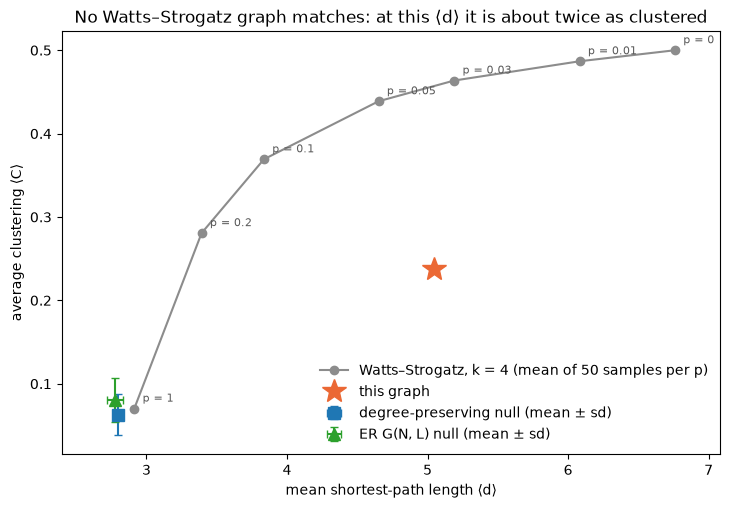

In [37]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.plot(ws["⟨d⟩ mean"], ws["⟨C⟩ mean"], "o-", color="0.55", lw=1.5, label="Watts–Strogatz, k = 4 (mean of 50 samples per p)")
for p, row in ws.iterrows():
    ax.annotate(f"p = {p:g}", (row["⟨d⟩ mean"], row["⟨C⟩ mean"]), textcoords="offset points", xytext=(6, 5),
                fontsize=8, color="0.35")
for name, null, color, marker in [("degree-preserving", null_dp, plt.cm.tab10(0), "s"), ("ER G(N, L)", null_er, plt.cm.tab10(2), "^")]:
    ax.errorbar(null["avg_path_length"].mean(), null["avg_clustering"].mean(), xerr=null["avg_path_length"].std(),
                yerr=null["avg_clustering"].std(), fmt=marker, color=color, ms=8, capsize=3, label=f"{name} null (mean ± sd)")
ax.plot(observed["avg_path_length"], observed["avg_clustering"], "*", color=ACCENT, ms=18, label="this graph")
ax.set_xlabel("mean shortest-path length ⟨d⟩")
ax.set_ylabel("average clustering ⟨C⟩")
ax.set_title("No Watts–Strogatz graph matches: at this ⟨d⟩ it is about twice as clustered")
ax.margins(x=0.08)  # room for the "p = 0" label
ax.legend(frameon=False, loc="lower right")
fig.savefig(FIG / "7_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

**Measurement:** Watts–Strogatz graphs with N = 51, k = 4 and p ∈ {0, 0.01, 0.03, 0.05, 0.1, 0.2, 1}, 50 connected samples per p (seeds 0–49): mean ⟨C⟩ and ⟨d⟩. Figure: `figures/7_model_comparison.png` places the graph, both nulls and the Watts–Strogatz curve in the (⟨d⟩, ⟨C⟩) plane.

**Observation:** The Watts–Strogatz curve runs from the lattice (p = 0: ⟨C⟩ = 0.50, ⟨d⟩ = 6.76) to almost random (p = 1: 0.07 and 2.91). It passes the graph's mean distance of 5.04 between p = 0.03 (⟨d⟩ = 5.19) and p = 0.05 (⟨d⟩ = 4.65), where its clustering is 0.46 and 0.44, about twice the graph's 0.238. Where its clustering comes closest to the graph's (p = 0.2, ⟨C⟩ = 0.28), its paths are much shorter (3.39). The graph lies well below the curve, and far from both nulls in the bottom-left corner.

**Interpretation:** The graph is not a small world. A small world combines high clustering with short, random-like paths (top left in the figure). This graph has long paths, more than half of the way from random (2.8) to the lattice (6.76), but only about half the clustering of a Watts–Strogatz graph with the same ⟨d⟩. This fits §5: the triangles are confined to a few dense patches, while the stretches between them (the corridor and the seams) are chain-like and contain almost no triangles.

**Caveat:** Watts–Strogatz with k = 4 has 102 links instead of 110. For N = 51 the curve is short, because even the lattice has ⟨d⟩ of only 6.76; the small-world window is much clearer in larger graphs. Small-world is ultimately a statement about how ⟨d⟩ grows with N (L4), which one graph of fixed size cannot test.

### 7.3 Verdict per model

Each model tests a different idea of how the graph could have arisen. The null models use 200 samples each (seeds 0–199); Watts–Strogatz uses 50 per p (seeds 0–49).

| Model | What it keeps fixed | Evidence for | Evidence against | Verdict |
|---|---|---|---|---|
| **Random:** ER G(N, L) (L4) | Only N = 51 and L = 110: "is it more than the density?" | Same sparsity. ⟨k⟩ = 4.31 > ln N = 3.93 puts ER near its connected regime (60 % of the samples are connected, §1.2). | ⟨C⟩ is about 3× the ER value (0.238 vs 0.081) and ⟨d⟩ 1.8× (5.04 vs 2.78). No hubs and no node with k ≤ 1, variance/mean 0.27 vs 0.85 (§3). Q 0.613 vs 0.398 (§6). 33 links (i, i+1) vs 4.4 (§7.1). | **Not random.** |
| **Degree-preserving** randomisation (L2, L4) | N, L and every node's degree: "is it more than the degree sequence?" | Reproduces the degrees exactly, by construction. | ⟨C⟩, ⟨d⟩, Q and the number of links (i, i+1) lie outside all 200 samples; r lies above them with p = 0.025 (§4). | **The structure is not explained by the degrees.** |
| **Small world:** Watts–Strogatz (L4) | N and k = 4 ≈ ⟨k⟩; p moves between lattice and random | ⟨C⟩ is far above random. | ⟨d⟩ = 5.04 is far from random (2.8) and from ln N / ln⟨k⟩ = 2.69, and more than half of the way to the lattice (6.76). Watts–Strogatz reaches this ⟨d⟩ only at p ≈ 0.03–0.05, where it is about twice as clustered; no p matches both numbers (§7.2). | **Not small-world**, but a lattice-like "large world" with local clustering. |
| **Scale-free** (L1) | A power-law degree distribution with hubs | None. | k_max = 6 and all degrees lie in 2–6, a factor of 3 rather than orders of magnitude. Variance/mean is 0.27, below even Poisson. ER graphs of the same size have larger hubs (k_max ≥ 7 in every sample, §3). | **Not scale-free.** With 5 distinct degree values a power-law fit would be meaningless, so none was attempted. |

**Overall:** On ⟨d⟩ and Q the graph is closest to the ring lattice; on ⟨C⟩ it lies between the lattice and random graphs. Together with the narrow degrees (§3) and the corridor (§2), this describes an elongated, lattice-like graph with clustering in a few dense patches. None of the three models captures this combination.

**Limitations:**
- N = 51 is small. Small-world and scale-free are statements about how a network scales with N, so a single graph of fixed size can only be checked for consistency with them.
- None of the models knows about space or the node order. The ring lattice is the only one with a built-in one-dimensional order, and it is the one that comes closest on ⟨d⟩ and Q (§8 looks at the order directly).
- The graph has no weights or coordinates, so "close in space" cannot be tested directly.
- Q depends on Louvain and its seed (§6), and Watts–Strogatz uses 102 instead of 110 links.

## 8. Beyond the summary: the node-ID backbone

The brief says that node IDs do not imply importance. They do seem to carry *position*, though: the adjacency matrix in §0 shows a band along the diagonal and stripes away from it. This section tests whether the ID order is real, and what it explains about the structure found in §1–§7.

### 8.1 A chain along the node IDs

In [38]:
backbone = [(i, i + 1) for i in nodes[:-1] if G.has_edge(i, i + 1)]
breaks = [(i, i + 1) for i in nodes[:-1] if not G.has_edge(i, i + 1)]
cons_null = null_dp["consecutive_id_edges"]
print(f"links (i, i+1): {len(backbone)} of {len(nodes) - 1} possible; degree-preserving null {cons_null.mean():.1f} ± "
      f"{cons_null.std():.1f} (max {cons_null.max()}), ER max {null_er['consecutive_id_edges'].max()}")
print("chain breaks (pairs i, i+1 without a link):", ", ".join(f"{i}–{j}" for i, j in breaks))

# Cut the ID sequence at every break: what is left are unbroken stretches of the chain
segments = []
for n in nodes:
    if segments and G.has_edge(n - 1, n):
        segments[-1].append(n)
    else:
        segments.append([n])

member = membership[f"Louvain (seed {SEED})"]
segment_rows = []
for s in segments:
    passed = sorted({member[n] for n in s})
    segment_rows.append({"stretch": f"{s[0]}–{s[-1]}" if len(s) > 1 else str(s[0]), "nodes": len(s),
                         "Louvain communities it passes through": len(passed)})
print(f"{len(segments)} stretches; the longest:")
pd.DataFrame(segment_rows).sort_values("nodes", ascending=False, kind="stable", ignore_index=True).head(5)

links (i, i+1): 33 of 50 possible; degree-preserving null 4.6 ± 2.0 (max 10), ER max 11
chain breaks (pairs i, i+1 without a link): 7–8, 9–10, 13–14, 16–17, 28–29, 31–32, 33–34, 34–35, 36–37, 37–38, 40–41, 41–42, 42–43, 44–45, 45–46, 47–48, 50–51
18 stretches; the longest:


,stretch,nodes,Louvain communities it passes through
0,17–28,12,5
1,1–7,7,2
2,10–13,4,2
3,14–16,3,1
4,29–31,3,1


In [39]:
# Are communities made of a few long ID stretches? Compare with random node sets of the same size
rng = np.random.default_rng(SEED)
run_rows = {}
for c in louvain:
    random_runs = [len(id_runs(rng.choice(nodes, size=len(c), replace=False))) for _ in range(1000)]
    run_rows[labels[frozenset(c)]] = {"size": len(c), "ID runs": len(id_runs(c)),
                                      "random sets: mean runs": np.mean(random_runs), "random sets: fewest runs": min(random_runs)}

print(f"chain links (i, i+1) inside one Louvain community: {sum(member[i] == member[j] for i, j in backbone)} of {len(backbone)}")
pd.DataFrame.from_dict(run_rows, orient="index").rename_axis("Louvain community (ID runs)").round(1)

chain links (i, i+1) inside one Louvain community: 27 of 33


,size,ID runs,random sets: mean runs,random sets: fewest runs
Louvain community (ID runs),,,,
"1–3, 17",4,2,3.8,1
"4–7, 20–22",7,2,6.2,4
"8–10, 23–26, 37, 41, 45, 51",11,6,8.8,4
"11–16, 27–31, 38–40, 48–50",17,4,11.6,6
"18–19, 32–36, 42–44, 46–47",12,4,9.4,5


**Measurement:** links between consecutive IDs (i, i+1), compared with the 200 degree-preserving and 200 ER samples (§1.2); the pairs without a link ("breaks"); the unbroken stretches between breaks and how many Louvain communities each passes through; and the number of ID runs per community (`id_runs`), compared with 1000 random node sets of the same size (`np.random.default_rng(SEED)`).

**Observation:**
- 33 of the 50 possible pairs (i, i+1) are linked, against 4.6 ± 2.0 in the degree-preserving null (at most 10 in 200 samples) and at most 11 in ER.
- The 17 breaks cut the IDs into 18 unbroken stretches. The longest are 17–28 (12 nodes) and 1–7 (7 nodes).
- Stretch 17–28 passes through all five Louvain communities in turn: 17 (tip), 18–19 (the group around 33–47), 20–22 ({4–7, 20–22}), 23–26 (core) and 27–28 (bottom-left module). It contains the corridor links 25–26 and 26–27 (§2).
- Every community consists of fewer ID runs than a random node set of its size has on average. Three of them have fewer runs than any of the 1000 random sets: {4–7, 20–22} (2 runs), the group around 33–47 (4) and the bottom-left module (4 runs: 11–16, 27–31, 38–40, 48–50, against 11.6 on average and never fewer than 6 for random 17-node sets).
- 27 of the 33 chain links lie inside one community.

**Interpretation:** The IDs are not arbitrary labels: they order the nodes along a chain, and the graph is that chain folded back on itself. The communities are a few stretches of the chain packed together, not random groups of nodes. The longest stretch runs from the top-right tip through every community into the bottom-left module, and part of the corridor (25–26–27) is this stretch itself. The bottleneck of §1–§2 is where the chain passes from the core into the module. This is consistent with the nodes being consecutive structural elements of one molecule, as in protein structure graphs (a hypothesis; the brief does not say what the nodes are).

**Caveat:** Both null models destroy the ID order by construction, so they show that the order is not chance, not what it means. A break may be a real gap in the chain or a link missing from the data; the graph alone cannot tell.

### 8.2 Stretches of the chain lying side by side

The stripes in the §0 matrix suggest that some stretches of the chain run alongside each other. Two stretches next to each other produce "ladders" of links: (i, j) together with (i+1, j+1) when they run in the same direction, or with (i+1, j−1) when they run in opposite directions.

In [40]:
ladder_rows = []
for H in [G] + refs_dp:
    links = {(min(u, v), max(u, v)) for u, v in H.edges()}
    rungs = set()  # links that belong to at least one ladder
    same, opposite = [], []
    for i, j in links:
        if j - i > 1 and (i + 1, j + 1) in links:  # stretches starting at i and j run in the same direction
            same.append((i, j))
            rungs |= {(i, j), (i + 1, j + 1)}
        if j - i > 2 and (i + 1, j - 1) in links:  # ... in opposite directions
            opposite.append((i, j))
            rungs |= {(i, j), (i + 1, j - 1)}
    ladder_rows.append({"ladder steps, same direction": len(same), "ladder steps, opposite direction": len(opposite),
                        "links in a ladder": len(rungs)})
    if H is G:
        g_rungs, g_same, g_opposite = rungs, sorted(same), sorted(opposite)

print("same direction:", ", ".join(f"{i}–{j}/{i + 1}–{j + 1}" for i, j in g_same))
print("opposite direction:", ", ".join(f"{i}–{j}/{i + 1}–{j - 1}" for i, j in g_opposite))
ladders = pd.DataFrame(ladder_rows)
pd.DataFrame({"observed": ladders.iloc[0], "degree-preserving mean": ladders.iloc[1:].mean(),
              "degree-preserving max": ladders.iloc[1:].max()}).round(1)

same direction: 3–34/4–35, 4–20/5–21, 5–19/6–20, 5–21/6–22, 6–20/7–21, 7–36/8–37, 8–23/9–24, 8–36/9–37, 9–24/10–25, 14–30/15–31, 15–29/16–30, 18–42/19–43, 23–44/24–45, 32–34/33–35, 32–42/33–43, 34–46/35–47, 38–49/39–50, 39–48/40–49, 41–45/42–46, 42–46/43–47
opposite direction: 3–34/4–33, 4–20/5–19, 5–21/6–20, 6–22/7–21, 8–25/9–24, 12–28/13–27, 12–40/13–39, 13–40/14–39, 14–30/15–29, 14–39/15–38, 15–31/16–30, 26–51/27–50, 27–50/28–49, 28–50/29–49, 29–49/30–48, 31–48/32–47, 32–47/33–46, 33–47/34–46, 35–44/36–43, 38–49/39–48, 39–50/40–49


,observed,degree-preserving mean,degree-preserving max
"ladder steps, same direction",20,8.7,17
"ladder steps, opposite direction",21,8.6,16
links in a ladder,57,30.8,48


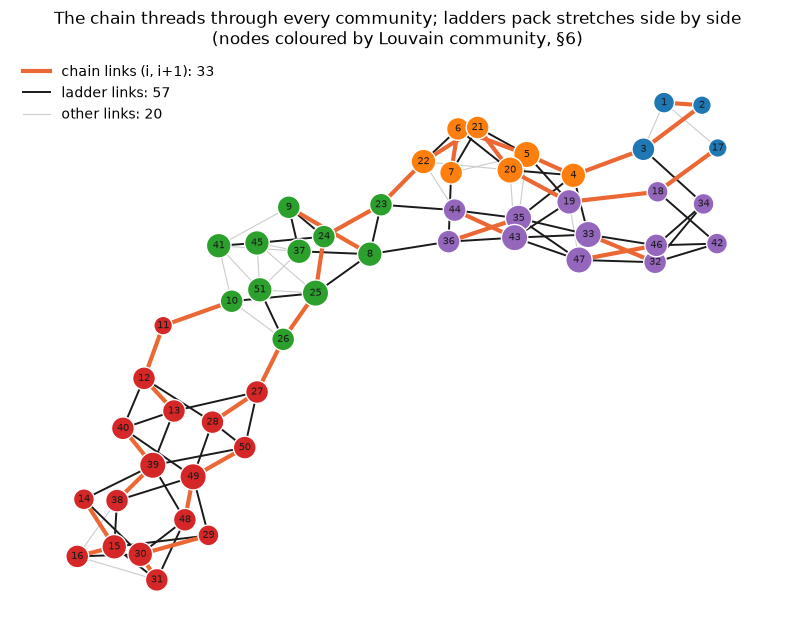

In [41]:
fig, ax = plt.subplots(figsize=(10, 7.5))
other = [(u, v) for u, v in G.edges() if abs(u - v) > 1 and (min(u, v), max(u, v)) not in g_rungs]
nx.draw_networkx_edges(G, pos, edgelist=other, ax=ax, edge_color="0.8", width=0.8)
nx.draw_networkx_edges(G, pos, edgelist=list(g_rungs), ax=ax, edge_color="#1a1a1a", width=1.4)
nx.draw_networkx_edges(G, pos, edgelist=backbone, ax=ax, edge_color=ACCENT, width=3)
nx.draw_networkx_nodes(G, pos, nodelist=nodes, ax=ax, node_color=[plt.cm.tab10(member[n]) for n in nodes],
                       edgecolors="white", node_size=[node_size(deg[n]) for n in nodes])
nx.draw_networkx_labels(G, pos, ax=ax, font_size=7, font_color="#1a1a1a")
ax.legend(handles=[plt.Line2D([], [], color=ACCENT, lw=3, label=f"chain links (i, i+1): {len(backbone)}"),
                   plt.Line2D([], [], color="#1a1a1a", lw=1.4, label=f"ladder links: {len(g_rungs)}"),
                   plt.Line2D([], [], color="0.8", lw=0.8, label=f"other links: {len(other)}")],
          loc="upper left", frameon=False)
ax.set_title("The chain threads through every community; ladders pack stretches side by side\n"
             "(nodes coloured by Louvain community, §6)")
ax.axis("off")
fig.savefig(FIG / "8_backbone_layout.png", dpi=150, bbox_inches="tight")
plt.show()

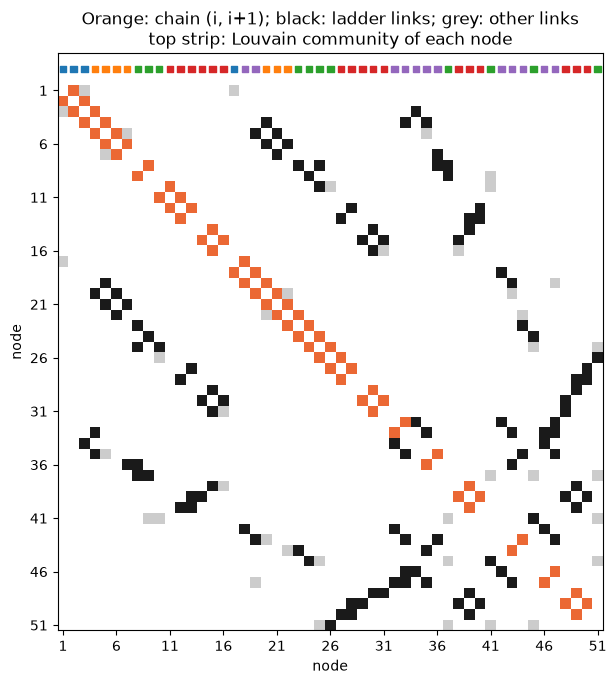

In [42]:
# The same three kinds of link in the adjacency matrix (ID order), with each node's Louvain community on top
idx = {n: k for k, n in enumerate(nodes)}
M = np.zeros((N, N))
for u, v in G.edges():
    if abs(u - v) == 1:
        kind = 3
    elif (min(u, v), max(u, v)) in g_rungs:
        kind = 2
    else:
        kind = 1
    M[idx[u], idx[v]] = M[idx[v], idx[u]] = kind

fig, ax = plt.subplots(figsize=(7.5, 7.5))
ax.imshow(M, cmap=ListedColormap(["white", "0.8", "#1a1a1a", ACCENT]), interpolation="nearest")
ax.scatter(range(N), [-2] * N, c=[plt.cm.tab10(member[n]) for n in nodes], marker="s", s=22, clip_on=False)
ax.set_ylim(N - 0.5, -3.5)
ax.set_xticks(ticks, [nodes[i] for i in ticks])
ax.set_yticks(ticks, [nodes[i] for i in ticks])
ax.set_xlabel("node")
ax.set_ylabel("node")
ax.set_title("Orange: chain (i, i+1); black: ladder links; grey: other links\ntop strip: Louvain community of each node")
fig.savefig(FIG / "8_backbone_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

**Measurement:** ladder steps, i.e. pairs of links (i, j) and (i+1, j+1) (same direction) or (i, j) and (i+1, j−1) (opposite direction) between non-consecutive nodes, and the number of links that belong to at least one ladder. Counted in the graph and in the 200 degree-preserving samples (seeds 0–199). Figures: `figures/8_backbone_layout.png` (shared layout) and `figures/8_backbone_matrix.png` (adjacency matrix in ID order).

**Observation:**
- The graph has 20 same-direction and 21 opposite-direction ladder steps, against 8.7 and 8.6 in the null (at most 17 and 16).
- 57 of its 110 links belong to a ladder, against 30.8 on average and at most 48 in the null. Together with the 33 chain links, 90 of the 110 links either follow the chain or belong to a ladder; only 20 are neither.
- In the matrix, the stripes away from the diagonal are almost all ladder links (black), and each community appears as a few blocks of IDs (top strip).
- Examples: 4–7 runs alongside 19–22 (4–20/5–21, 5–21/6–22, 6–20/7–21 and more), and 8–10 alongside 23–25 (8–23/9–24, 9–24/10–25). In the bottom-left module, 12–15 runs alongside 38–40 in the opposite direction (12–40/13–39, 13–40/14–39, 14–39/15–38), and 26–30 alongside 48–51 (26–51/27–50, 27–50/28–49, 28–50/29–49, 29–49/30–48).

**Interpretation:** The chain is not only folded: long stretches of it lie side by side, in the same or the opposite direction, and these pairings account for most of the links that are not on the chain. This ties the earlier results together:
- **Communities (§6):** a community is a few stretches packed side by side, such as 12–15 with 38–40, and 26–30 with 48–51, in the bottom-left module.
- **Clustering (§5, §7):** a ladder step forms a square with the chain links, (i, i+1, j+1, j), not a triangle. Packing by ladders is consistent with lattice-like long paths but only about half the clustering of a Watts–Strogatz graph with the same ⟨d⟩.
- **Corridor (§2):** its links are chain links (25–26, 26–27) or ladder links (36–8 in 8–36/9–37, 8–25 in 8–25/9–24).

In protein contact maps, stretches lying side by side like this are what paired β-strands look like (again a hypothesis, not stated in the brief).

**Caveat:** The degree-preserving null also removes the chain, so part of the ladder excess may follow from the chain alone; a stricter null would keep the 33 chain links fixed and shuffle only the rest. "Ladder" is a definition made for this analysis, not a measure from the lectures.

## Key claims

Each claim rests on at least two independent pieces of evidence from this graph. The section numbers point to the code outputs, and the figures make the nodes locatable on the shared layout.

1. **The bottom-left module {11–16, 27–31, 38–40, 48–50} is attached to the rest of the graph by only two links:** 26–27 and 10–11 (or 11–12 when node 11 is assigned to the core). Removing 26 or 27 together with 10, 11 or 12 cuts it off (§1). In greedy (without node 11) it is the only strong community, with 33 links inside and 2 leaving (§6.2). Louvain finds it unchanged in all 100 runs (§6.3). It consists of four chain stretches packed side by side (§8). Figures: `1_node_cut.png`, `6_communities.png`, `6_stability.png`.
2. **Shortest paths between the two ends of the graph funnel through the corridor 36–8–25–26–27.** All 504 shortest paths between the 20 most distant pairs pass through these five nodes (§1). Each of its four links carries 34–39 % of all shortest paths, about twice as much as the next link (§2.2), and three of the four lie in no triangle (§5). Betweenness therefore ranks the k = 4 nodes 26, 27 and 36 among the top five, while degree cannot separate the nine k = 6 nodes (§2.1, §2.3). Figures: `1_eccentricity.png`, `2_centralities.png`, `5_clustering.png`.
3. **The node IDs encode a chain that is folded and packed side by side.** 33 of the 50 pairs (i, i+1) are linked, against 4.6 ± 2.0 expected (at most 10 in 200 samples). Every community consists of fewer ID runs than random node sets of its size. 57 links form ladders between stretches lying side by side, against 30.8 expected (at most 48), so chain and ladder links together make up 90 of the 110 links (§8). Figures: `8_backbone_layout.png`, `8_backbone_matrix.png`.
4. **The graph is a lattice-like "large world", not a small world.** Clustering is high (⟨C⟩ = 0.238 against 0.063 in the degree-preserving null, §5), but paths are long (⟨d⟩ = 5.04 against 2.80, diameter 12; §1, §7). Watts–Strogatz reaches this ⟨d⟩ only where it is about twice as clustered, and no rewiring probability matches both numbers (§7.2). Figure: `7_model_comparison.png`.
5. **The degrees are narrow and there are no hubs, so the graph is not scale-free.** All degrees lie in 2–6 and variance/mean is 0.27, about a quarter of the Poisson value. None of the 200 ER graphs with the same N and L is as narrow: all have k_max ≥ 7, and the lowest variance/mean among them is 0.47 (§3, §7.3). Degree is also a poor guide to importance here (claim 2). Figure: `3_degree_distribution.png`.